In [1]:

# Step 1: Import libraries and verify the project directory

from pathlib import Path
import pandas as pd
import zipfile

PROJECT_DIR = Path(r"E:\Projects_website\Liminal Portfolio\Project 2")

print("Project directory exists:", PROJECT_DIR.exists())
print("CFPB file exists:", (PROJECT_DIR / "cfpb_data.csv").exists())
print("FTC folder exists:", (PROJECT_DIR / "ftc_data").exists())

print("\nFiles in Project 2:")
for path in sorted(PROJECT_DIR.iterdir()):
    print(path.name)


Project directory exists: True
CFPB file exists: True
FTC folder exists: True

Files in Project 2:
.ipynb_checkpoints
01_consumer_fraud_data_audit.ipynb
cfpb_data.csv
ftc_data


In [9]:

# Step 8: Combine the two CFPB exports

file1 = PROJECT_DIR / "cfpb_part1.csv"
file2 = PROJECT_DIR / "cfpb_part2.csv"

part1 = pd.read_csv(file1, low_memory=False)
part2 = pd.read_csv(file2, low_memory=False)

print("Part 1 shape:", part1.shape)
print("Part 2 shape:", part2.shape)

# Verify both exports have the same columns
assert set(part1.columns) == set(part2.columns), \
    "The two files have different columns."

# Combine records
cfpb_combined = pd.concat(
    [part1, part2],
    ignore_index=True
)

# Convert dates to timezone-aware datetime values
cfpb_combined["Date received"] = pd.to_datetime(
    cfpb_combined["Date received"],
    utc=True,
    errors="coerce"
)

# Validate dates
print("\nInvalid dates:", cfpb_combined["Date received"].isna().sum())

# Check duplicate complaint IDs across both files
print(
    "Duplicate Complaint IDs:",
    cfpb_combined["Complaint ID"].duplicated().sum()
)

# Sort chronologically, oldest to newest
cfpb_combined = cfpb_combined.sort_values(
    "Date received",
    ascending=True
).reset_index(drop=True)

# Save as a new file. Do not overwrite the original exports.
output_path = PROJECT_DIR / "cfpb_combined_sorted.csv"
cfpb_combined.to_csv(output_path, index=False)

print("\nFinal shape:", cfpb_combined.shape)
print("First date:", cfpb_combined["Date received"].min())
print("Last date:", cfpb_combined["Date received"].max())
print(
    "Chronologically sorted:",
    cfpb_combined["Date received"].is_monotonic_increasing
)
print("Saved to:", output_path)


Part 1 shape: (99556, 15)
Part 2 shape: (58637, 15)

Invalid dates: 0
Duplicate Complaint IDs: 0

Final shape: (158193, 15)
First date: 2020-01-01 00:55:59+00:00
Last date: 2025-12-31 23:46:29+00:00
Chronologically sorted: True
Saved to: E:\Projects_website\Liminal Portfolio\Project 2\cfpb_combined_sorted.csv


In [10]:

# Inspect the actual issue/sub-issue combinations

print("Product x Issue:")
display(pd.crosstab(
    cfpb_combined["Product"],
    cfpb_combined["Issue"]
))

print("\nDebt collection sub-issues:")
display(
    cfpb_combined.loc[
        cfpb_combined["Product"] == "Debt collection",
        "Sub-issue"
    ].value_counts(dropna=False)
)

print("\nCredit card sub-issues:")
display(
    cfpb_combined.loc[
        cfpb_combined["Product"] == "Credit card or prepaid card",
        "Sub-issue"
    ].value_counts(dropna=False)
)


Product x Issue:


Issue,Attempts to collect debt not owed,Fraud or scam,Getting a credit card,Unauthorized transactions or other transaction problem
Product,,,,
Credit card or prepaid card,0,0,9240,0
Debt collection,101822,0,0,0
"Money transfer, virtual currency, or money service",0,34882,0,12249



Debt collection sub-issues:


Sub-issue
Debt was result of identity theft    101822
Name: count, dtype: int64


Credit card sub-issues:


Sub-issue
Card opened as result of identity theft or fraud    9240
Name: count, dtype: int64

In [11]:

# Step 9: Establish the baseline for the rebuilt extract

# Annual complaint counts by product
annual_product = pd.crosstab(
    cfpb_combined["Date received"].dt.year,
    cfpb_combined["Product"]
)

print("Annual complaints by product")
display(annual_product)

# Annual counts by issue
annual_issue = pd.crosstab(
    cfpb_combined["Date received"].dt.year,
    cfpb_combined["Issue"]
)

print("\nAnnual complaints by issue")
display(annual_issue)

# Monthly counts for the full period
monthly_counts = (
    cfpb_combined
    .set_index("Date received")
    .resample("MS")
    .size()
    .rename("Complaints")
)

print("\nMonthly coverage check")
print("Number of months:", len(monthly_counts))
print("Months with zero records:", (monthly_counts == 0).sum())

print("\nFirst 6 months")
display(monthly_counts.head(6).to_frame())

print("\nLast 6 months")
display(monthly_counts.tail(6).to_frame())


Annual complaints by product


Product,Credit card or prepaid card,Debt collection,"Money transfer, virtual currency, or money service"
Date received,,,
2020,1145,8643,3361
2021,1621,13839,4952
2022,3485,9324,7221
2023,2989,11427,6827
2024,0,19758,7833
2025,0,38831,16937



Annual complaints by issue


Issue,Attempts to collect debt not owed,Fraud or scam,Getting a credit card,Unauthorized transactions or other transaction problem
Date received,,,,
2020,8643,2398,1145,963
2021,13839,3804,1621,1148
2022,9324,5933,3485,1288
2023,11427,5395,2989,1432
2024,19758,6173,0,1660
2025,38831,11179,0,5758



Monthly coverage check
Number of months: 72
Months with zero records: 0

First 6 months


,Complaints
Date received,
2020-01-01 00:00:00+00:00,721
2020-02-01 00:00:00+00:00,845
2020-03-01 00:00:00+00:00,1037
2020-04-01 00:00:00+00:00,1205
2020-05-01 00:00:00+00:00,1148
2020-06-01 00:00:00+00:00,1198



Last 6 months


,Complaints
Date received,
2025-07-01 00:00:00+00:00,4902
2025-08-01 00:00:00+00:00,5660
2025-09-01 00:00:00+00:00,5298
2025-10-01 00:00:00+00:00,4215
2025-11-01 00:00:00+00:00,4464
2025-12-01 00:00:00+00:00,4897


In [12]:

# Step 10: Diagnose product coverage and export boundaries

print("Credit-card records by year:")
display(
    cfpb_combined.loc[
        cfpb_combined["Product"] == "Credit card or prepaid card"
    ]
    .groupby(cfpb_combined["Date received"].dt.year)
    .size()
    .rename("Complaints")
    .to_frame()
)

print("\nDate range by original export:")

for name, df in [("Part 1", part1), ("Part 2", part2)]:
    dates = pd.to_datetime(df["Date received"], utc=True, errors="coerce")
    print(
        name,
        "| rows:", len(df),
        "| first:", dates.min(),
        "| last:", dates.max()
    )

print("\nCredit-card date range:")
cards = cfpb_combined[
    cfpb_combined["Product"] == "Credit card or prepaid card"
]
print("First:", cards["Date received"].min())
print("Last:", cards["Date received"].max())


Credit-card records by year:


,Complaints
Date received,
2020,1145
2021,1621
2022,3485
2023,2989



Date range by original export:
Part 1 | rows: 99556 | first: 2020-01-01 00:55:59+00:00 | last: 2024-11-30 23:10:00+00:00
Part 2 | rows: 58637 | first: 2024-12-01 00:09:22+00:00 | last: 2025-12-31 23:46:29+00:00

Credit-card date range:
First: 2020-01-01 21:31:11+00:00
Last: 2023-08-24 22:29:26+00:00


In [13]:

# Step 11: Check credit-card coverage in each export

for name, df in [("Part 1", part1), ("Part 2", part2)]:
    print(f"\n--- {name} ---")

    cards = df[
        df["Product"] == "Credit card or prepaid card"
    ].copy()

    print("Credit-card rows:", len(cards))

    if len(cards) > 0:
        cards["Date received"] = pd.to_datetime(
            cards["Date received"], utc=True, errors="coerce"
        )
        print("First date:", cards["Date received"].min())
        print("Last date:", cards["Date received"].max())

        print("\nCounts by year:")
        display(
            cards.groupby(cards["Date received"].dt.year)
            .size()
            .rename("Complaints")
            .to_frame()
        )



--- Part 1 ---
Credit-card rows: 9240
First date: 2020-01-01 21:31:11+00:00
Last date: 2023-08-24 22:29:26+00:00

Counts by year:


,Complaints
Date received,
2020,1145
2021,1621
2022,3485
2023,2989



--- Part 2 ---
Credit-card rows: 0


In [14]:

# Step 12: Annual trend analysis

df = cfpb_combined.copy()

df["Year"] = df["Date received"].dt.year

# Annual counts by product
annual_product = (
    df.groupby(["Year", "Product"])
      .size()
      .unstack(fill_value=0)
      .sort_index()
)

# Annual counts by issue
annual_issue = (
    df.groupby(["Year", "Issue"])
      .size()
      .unstack(fill_value=0)
      .sort_index()
)

print("ANNUAL COMPLAINTS BY PRODUCT")
display(annual_product)

print("\nYEAR-ON-YEAR CHANGE BY PRODUCT (%)")
display(
    annual_product.pct_change(fill_method=None)
    .mul(100)
    .round(1)
)

print("\nANNUAL COMPLAINTS BY ISSUE")
display(annual_issue)

print("\nYEAR-ON-YEAR CHANGE BY ISSUE (%)")
display(
    annual_issue.pct_change(fill_method=None)
    .mul(100)
    .round(1)
)


ANNUAL COMPLAINTS BY PRODUCT


Product,Credit card or prepaid card,Debt collection,"Money transfer, virtual currency, or money service"
Year,,,
2020,1145,8643,3361
2021,1621,13839,4952
2022,3485,9324,7221
2023,2989,11427,6827
2024,0,19758,7833
2025,0,38831,16937



YEAR-ON-YEAR CHANGE BY PRODUCT (%)


Product,Credit card or prepaid card,Debt collection,"Money transfer, virtual currency, or money service"
Year,,,
2020,NaN,NaN,NaN
2021,41.6,60.1,47.3
2022,115.0,-32.6,45.8
2023,-14.2,22.6,-5.5
2024,-100.0,72.9,14.7
2025,NaN,96.5,116.2



ANNUAL COMPLAINTS BY ISSUE


Issue,Attempts to collect debt not owed,Fraud or scam,Getting a credit card,Unauthorized transactions or other transaction problem
Year,,,,
2020,8643,2398,1145,963
2021,13839,3804,1621,1148
2022,9324,5933,3485,1288
2023,11427,5395,2989,1432
2024,19758,6173,0,1660
2025,38831,11179,0,5758



YEAR-ON-YEAR CHANGE BY ISSUE (%)


Issue,Attempts to collect debt not owed,Fraud or scam,Getting a credit card,Unauthorized transactions or other transaction problem
Year,,,,
2020,NaN,NaN,NaN,NaN
2021,60.1,58.6,41.6,19.2
2022,-32.6,56.0,115.0,12.2
2023,22.6,-9.1,-14.2,11.2
2024,72.9,14.4,-100.0,15.9
2025,96.5,81.1,NaN,246.9


C:\Users\admin\AppData\Local\Temp\ipykernel_17060\3189631807.py:6: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df["Month"] = df["Date received"].dt.to_period("M").astype(str)


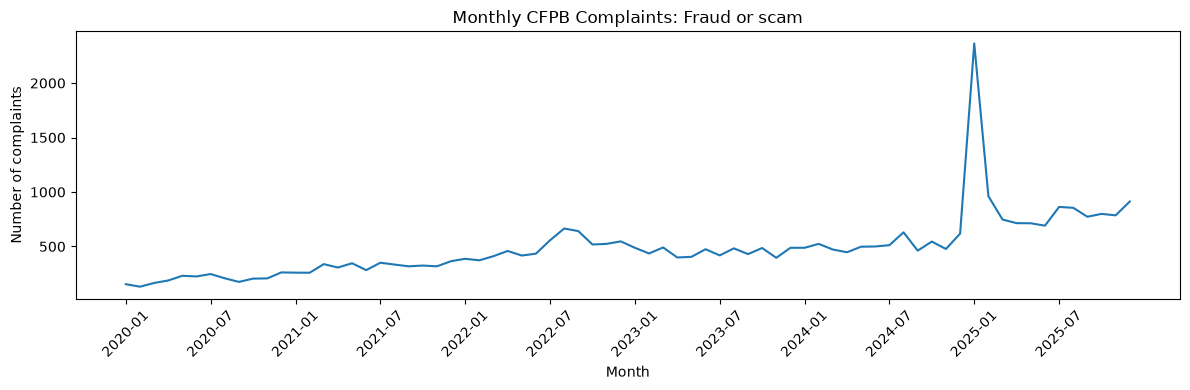

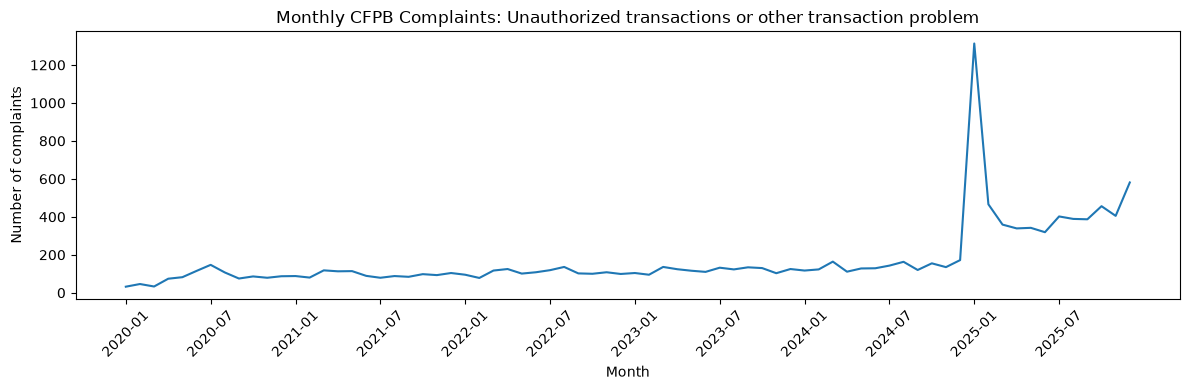

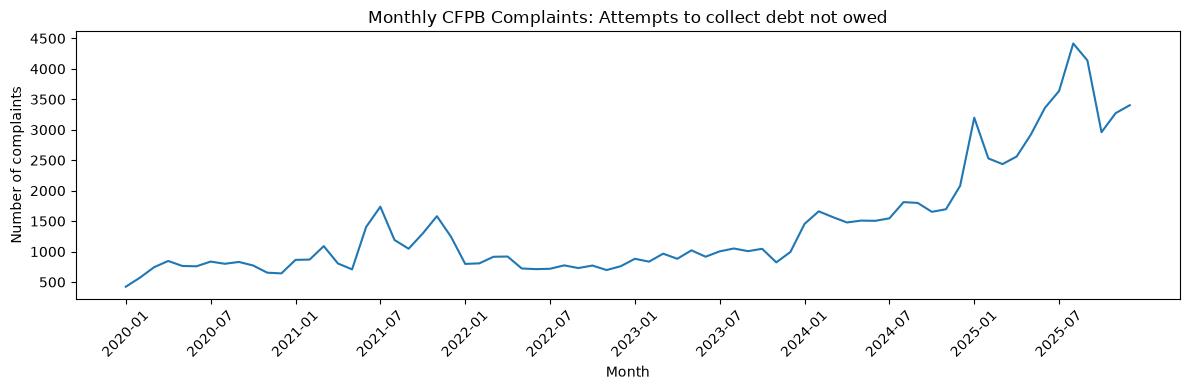

In [15]:

# Step 13: Monthly trends for the two main categories

import matplotlib.pyplot as plt

df = cfpb_combined.copy()
df["Month"] = df["Date received"].dt.to_period("M").astype(str)

monthly = (
    df.groupby(["Month", "Issue"])
      .size()
      .unstack(fill_value=0)
      .sort_index()
)

issues_to_plot = [
    "Fraud or scam",
    "Unauthorized transactions or other transaction problem",
    "Attempts to collect debt not owed"
]

for issue in issues_to_plot:
    if issue in monthly.columns:
        plt.figure(figsize=(12, 4))
        plt.plot(monthly.index, monthly[issue])
        plt.title(f"Monthly CFPB Complaints: {issue}")
        plt.xlabel("Month")
        plt.ylabel("Number of complaints")
        plt.xticks(
            range(0, len(monthly.index), 6),
            monthly.index[::6],
            rotation=45
        )
        plt.tight_layout()
        plt.show()


In [16]:

# Step 14A: January spike diagnostic

df = cfpb_combined.copy()
df["Date received"] = pd.to_datetime(df["Date received"], utc=True)
df["Year"] = df["Date received"].dt.year
df["Month"] = df["Date received"].dt.month

issues = [
    "Fraud or scam",
    "Unauthorized transactions or other transaction problem",
    "Attempts to collect debt not owed"
]

# Compare each month of 2024 and 2025
monthly_compare = (
    df[df["Year"].isin([2024, 2025])]
    .groupby(["Year", "Month", "Issue"])
    .size()
    .unstack("Year", fill_value=0)
)

monthly_compare["YoY change (%)"] = (
    (monthly_compare[2025] - monthly_compare[2024])
    / monthly_compare[2024].replace(0, float("nan"))
    * 100
).round(1)

print("Monthly comparison by issue")
display(monthly_compare.loc[
    monthly_compare.index.get_level_values("Issue").isin(issues)
])


Monthly comparison by issue


Year                                                      2024  2025  \
Month Issue                                                            
1     Attempts to collect debt not owed                   1455  3198   
      Fraud or scam                                        488  2363   
      Unauthorized transactions or other transaction ...   117  1313   
2     Attempts to collect debt not owed                   1661  2529   
      Fraud or scam                                        524   962   
      Unauthorized transactions or other transaction ...   123   466   
3     Attempts to collect debt not owed                   1566  2436   
      Fraud or scam                                        472   747   
      Unauthorized transactions or other transaction ...   164   359   
4     Attempts to collect debt not owed                   1478  2561   
      Fraud or scam                                        447   714   
      Unauthorized transactions or other transaction ...   111   339   
5     Attempts to collect debt not owed                   1509  2920   
      Fraud or scam                                        498   713   
      Unauthorized transactions or other transaction ...   128   342   
6     Attempts to collect debt not owed                   1505  3360   
      Fraud or scam                                        500   691   
      Unauthorized transactions or other transaction ...   129   319   
7     Attempts to collect debt not owed                   1546  3637   
      Fraud or scam                                        512   863   
      Unauthorized transactions or other transaction ...   143   402   
8     Attempts to collect debt not owed                   1812  4416   
      Fraud or scam                                        630   855   
      Unauthorized transactions or other transaction ...   163   389   
9     Attempts to collect debt not owed                   1799  4138   
      Fraud or scam                                        462   773   
      Unauthorized transactions or other transaction ...   120   387   
10    Attempts to collect debt not owed                   1653  2960   
      Fraud or scam                                        545   799   
      Unauthorized transactions or other transaction ...   155   456   
11    Attempts to collect debt not owed                   1695  3273   
      Fraud or scam                                        477   786   
      Unauthorized transactions or other transaction ...   135   405   
12    Attempts to collect debt not owed                   2079  3403   
      Fraud or scam                                        618   913   
      Unauthorized transactions or other transaction ...   172   581   

Year                                                      YoY change (%)  
Month Issue                                                               
1     Attempts to collect debt not owed                            119.8  
      Fraud or scam                                                384.2  
      Unauthorized transactions or other transaction ...          1022.2  
2     Attempts to collect debt not owed                             52.3  
      Fraud or scam                                                 83.6  
      Unauthorized transactions or other transaction ...           278.9  
3     Attempts to collect debt not owed                             55.6  
      Fraud or scam                                                 58.3  
      Unauthorized transactions or other transaction ...           118.9  
4     Attempts to collect debt not owed                             73.3  
      Fraud or scam                                                 59.7  
      Unauthorized transactions or other transaction ...           205.4  
5     Attempts to collect debt not owed                             93.5  
      Fraud or scam                                                 43.2  
      Unauthorized transactions or other transaction ...       

In [17]:

# Step 14B: Company concentration in January 2025

jan25 = df[
    (df["Year"] == 2025)
    & (df["Month"] == 1)
    & (df["Issue"].isin(issues))
].copy()

jan24 = df[
    (df["Year"] == 2024)
    & (df["Month"] == 1)
    & (df["Issue"].isin(issues))
].copy()

for issue in issues:
    print(f"\n--- {issue} ---")

    current = (
        jan25[jan25["Issue"] == issue]["Company"]
        .value_counts()
        .rename("Jan 2025")
    )

    previous = (
        jan24[jan24["Issue"] == issue]["Company"]
        .value_counts()
        .rename("Jan 2024")
    )

    comparison = pd.concat([current, previous], axis=1).fillna(0)
    comparison["Change"] = comparison["Jan 2025"] - comparison["Jan 2024"]

    print("Top companies in January 2025:")
    display(comparison.sort_values("Jan 2025", ascending=False).head(10))

    print("January 2025 complaints:", int(comparison["Jan 2025"].sum()))
    print("January 2024 complaints:", int(comparison["Jan 2024"].sum()))
    print("Number of companies in Jan 2025:", len(current))




--- Fraud or scam ---
Top companies in January 2025:


,Jan 2025,Jan 2024,Change
Company,,,
"Block, Inc.",817.0,42.0,775.0
"Early Warning Services, LLC",757.0,19.0,738.0
JPMORGAN CHASE & CO.,174.0,69.0,105.0
"BANK OF AMERICA, NATIONAL ASSOCIATION",115.0,49.0,66.0
WELLS FARGO & COMPANY,109.0,43.0,66.0
"Paypal Holdings, Inc",76.0,47.0,29.0
"Coinbase, Inc.",40.0,25.0,15.0
PNC Bank N.A.,21.0,5.0,16.0
NAVY FEDERAL CREDIT UNION,19.0,8.0,11.0


January 2025 complaints: 2363
January 2024 complaints: 488
Number of companies in Jan 2025: 85

--- Unauthorized transactions or other transaction problem ---
Top companies in January 2025:


,Jan 2025,Jan 2024,Change
Company,,,
"Block, Inc.",679.0,28.0,651.0
"Early Warning Services, LLC",332.0,0.0,332.0
JPMORGAN CHASE & CO.,73.0,5.0,68.0
"Paypal Holdings, Inc",68.0,40.0,28.0
"BANK OF AMERICA, NATIONAL ASSOCIATION",40.0,3.0,37.0
WELLS FARGO & COMPANY,34.0,5.0,29.0
Chime Financial Inc,14.0,12.0,2.0
NAVY FEDERAL CREDIT UNION,8.0,0.0,8.0
CAPITAL ONE FINANCIAL CORPORATION,8.0,0.0,8.0


January 2025 complaints: 1313
January 2024 complaints: 117
Number of companies in Jan 2025: 48

--- Attempts to collect debt not owed ---
Top companies in January 2025:


,Jan 2025,Jan 2024,Change
Company,,,
Experian Information Solutions Inc.,440.0,192.0,248.0
"TRANSUNION INTERMEDIATE HOLDINGS, INC.",419.0,212.0,207.0
"EQUIFAX, INC.",394.0,158.0,236.0
Resurgent Capital Services L.P.,183.0,85.0,98.0
ENCORE CAPITAL GROUP INC.,102.0,42.0,60.0
CL Holdings LLC,94.0,31.0,63.0
"Portfolio Recovery Associates, LLC",74.0,30.0,44.0
CAPITAL ONE FINANCIAL CORPORATION,63.0,18.0,45.0
TRANSWORLD SYSTEMS INC,54.0,24.0,30.0


January 2025 complaints: 3198
January 2024 complaints: 1455
Number of companies in Jan 2025: 331


In [18]:

# Step 15: Company concentration across 2024 and 2025

df = cfpb_combined.copy()
df["Year"] = df["Date received"].dt.year

issues = [
    "Fraud or scam",
    "Unauthorized transactions or other transaction problem"
]

for issue in issues:
    subset = df[df["Issue"] == issue]

    print(f"\n{'=' * 60}")
    print(issue)

    for year in [2024, 2025]:
        yearly = subset[subset["Year"] == year]
        company_counts = yearly["Company"].value_counts()

        total = len(yearly)
        top2 = company_counts.head(2).sum()
        top5 = company_counts.head(5).sum()

        print(f"\nYear: {year}")
        print("Total complaints:", total)
        print("Distinct companies:", company_counts.size)
        print("Top 2 share (%):", round(top2 / total * 100, 1))
        print("Top 5 share (%):", round(top5 / total * 100, 1))

        display(
            company_counts.head(10)
            .rename("Complaints")
            .to_frame()
        )



Fraud or scam

Year: 2024
Total complaints: 6173
Distinct companies: 268
Top 2 share (%): 22.2
Top 5 share (%): 50.4


,Complaints
Company,
"Paypal Holdings, Inc",691
JPMORGAN CHASE & CO.,677
WELLS FARGO & COMPANY,617
"Block, Inc.",602
"BANK OF AMERICA, NATIONAL ASSOCIATION",527
"Coinbase, Inc.",301
"Early Warning Services, LLC",286
"CITIBANK, N.A.",178
Chime Financial Inc,173



Year: 2025
Total complaints: 11179
Distinct companies: 286
Top 2 share (%): 38.5
Top 5 share (%): 63.9


,Complaints
Company,
"Block, Inc.",3051
"Early Warning Services, LLC",1254
"Paypal Holdings, Inc",1127
JPMORGAN CHASE & CO.,860
WELLS FARGO & COMPANY,846
"BANK OF AMERICA, NATIONAL ASSOCIATION",684
Chime Financial Inc,508
"Coinbase, Inc.",379
ROBINHOOD MARKETS INC.,137



Unauthorized transactions or other transaction problem

Year: 2024
Total complaints: 1660
Distinct companies: 87
Top 2 share (%): 63.4
Top 5 share (%): 79.2


,Complaints
Company,
"Paypal Holdings, Inc",564
"Block, Inc.",488
Chime Financial Inc,101
JPMORGAN CHASE & CO.,95
WELLS FARGO & COMPANY,67
"Early Warning Services, LLC",52
"BANK OF AMERICA, NATIONAL ASSOCIATION",37
"Coinbase, Inc.",17
Google Compare Credit Cards Inc.,14



Year: 2025
Total complaints: 5758
Distinct companies: 118
Top 2 share (%): 70.4
Top 5 share (%): 86.7


,Complaints
Company,
"Block, Inc.",2803
"Paypal Holdings, Inc",1249
"Early Warning Services, LLC",461
Chime Financial Inc,296
JPMORGAN CHASE & CO.,185
WELLS FARGO & COMPANY,131
"BANK OF AMERICA, NATIONAL ASSOCIATION",103
Google Compare Credit Cards Inc.,36
ROBINHOOD MARKETS INC.,29



Monthly counts: Fraud or scam


C:\Users\admin\AppData\Local\Temp\ipykernel_17060\359565254.py:6: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df["Month"] = df["Date received"].dt.to_period("M").astype(str)


Company,"Block, Inc.","Early Warning Services, LLC",JPMORGAN CHASE & CO.,"Paypal Holdings, Inc"
Month,,,,
2024-01,42,19,69,47
2024-02,48,20,65,58
2024-03,51,17,49,47
2024-04,48,12,49,51
2024-05,40,11,54,59
2024-06,46,24,48,63
2024-07,51,17,67,66
2024-08,61,51,70,58
2024-09,30,14,51,52


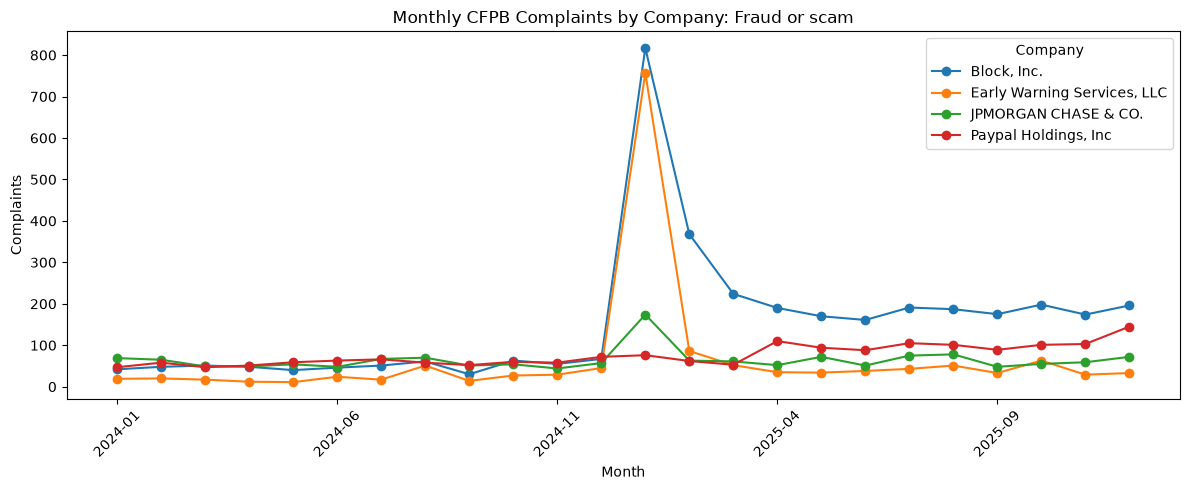


Monthly counts: Unauthorized transactions or other transaction problem


Company,"Block, Inc.",Chime Financial Inc,"Early Warning Services, LLC","Paypal Holdings, Inc"
Month,,,,
2024-01,28,12,0,40
2024-02,36,8,6,43
2024-03,51,4,6,56
2024-04,38,9,3,36
2024-05,44,8,5,47
2024-06,40,7,3,41
2024-07,32,18,3,49
2024-08,59,9,6,50
2024-09,33,2,3,42


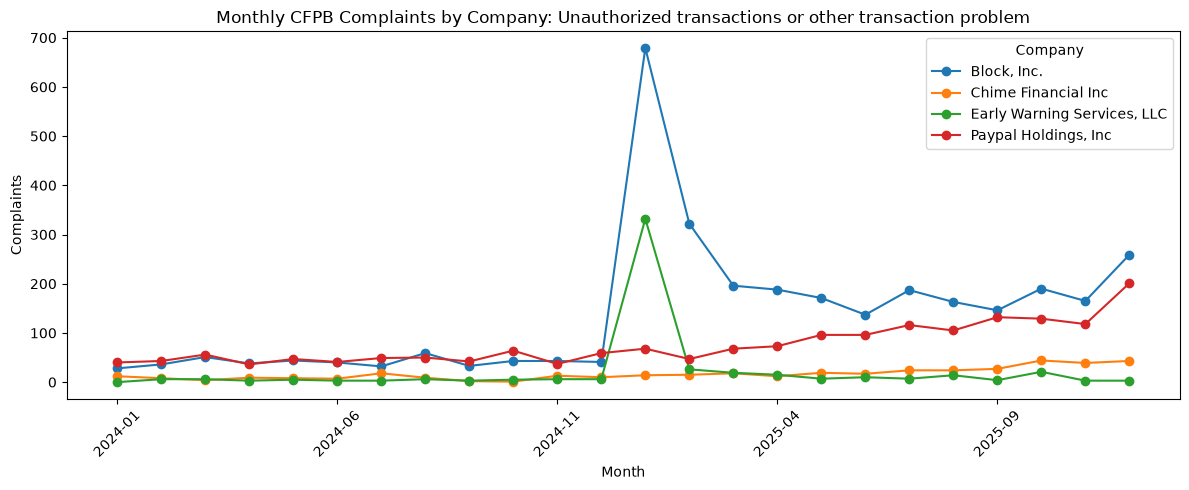

In [19]:

# Step 16: Monthly complaint trends for leading companies

import matplotlib.pyplot as plt

df = cfpb_combined.copy()
df["Month"] = df["Date received"].dt.to_period("M").astype(str)

company_issue_pairs = {
    "Fraud or scam": [
        "Block, Inc.",
        "Early Warning Services, LLC",
        "Paypal Holdings, Inc",
        "JPMORGAN CHASE & CO."
    ],
    "Unauthorized transactions or other transaction problem": [
        "Block, Inc.",
        "Paypal Holdings, Inc",
        "Early Warning Services, LLC",
        "Chime Financial Inc"
    ]
}

for issue, companies in company_issue_pairs.items():
    subset = df[
        (df["Issue"] == issue)
        & (df["Company"].isin(companies))
        & (df["Date received"].dt.year.isin([2024, 2025]))
    ]

    trend = (
        subset.groupby(["Month", "Company"])
        .size()
        .unstack(fill_value=0)
        .sort_index()
    )

    print(f"\nMonthly counts: {issue}")
    display(trend)

    ax = trend.plot(figsize=(12, 5), marker="o", linewidth=1.5)
    ax.set_title(f"Monthly CFPB Complaints by Company: {issue}")
    ax.set_xlabel("Month")
    ax.set_ylabel("Complaints")
    ax.tick_params(axis="x", rotation=45)
    plt.tight_layout()
    plt.show()


In [20]:

# Step 17: Inspect complaint metadata around the January spike

df = cfpb_combined.copy()
df["Date received"] = pd.to_datetime(df["Date received"], utc=True)

companies = ["Block, Inc.", "Early Warning Services, LLC"]
issues = [
    "Fraud or scam",
    "Unauthorized transactions or other transaction problem"
]

periods = {
    "Dec 2024": ("2024-12-01", "2025-01-01"),
    "Jan 2025": ("2025-01-01", "2025-02-01"),
    "Feb 2025": ("2025-02-01", "2025-03-01")
}

for company in companies:
    for issue in issues:
        subset = df[
            (df["Company"] == company)
            & (df["Issue"] == issue)
        ]

        print(f"\n--- {company} | {issue} ---")

        for period, (start, end) in periods.items():
            records = subset[
                (subset["Date received"] >= start)
                & (subset["Date received"] < end)
            ]

            print(f"\n{period}: {len(records)} complaints")

            if len(records):
                print("Submission channel:")
                display(records["Submitted via"].value_counts(dropna=False))

                print("Company response:")
                display(
                    records["Company response to consumer"]
                    .value_counts(dropna=False)
                )

                print("Timely response:")
                display(records["Timely response?"].value_counts(dropna=False))



--- Block, Inc. | Fraud or scam ---

Dec 2024: 67 complaints
Submission channel:


Submitted via
Web         62
Phone        3
Referral     2
Name: count, dtype: int64

Company response:


Company response to consumer
Closed with explanation    67
Name: count, dtype: int64

Timely response:


...

Submitted via
Web      25
Phone     1
Name: count, dtype: int64

Company response:


Company response to consumer
Closed with explanation    26
Name: count, dtype: int64

Timely response:


Timely response?
Yes    26
Name: count, dtype: int64

In [21]:

# Step 18: Check whether narratives or other explanatory fields are available

print("Available columns:")
print(cfpb_combined.columns.tolist())

# Compare company-response labels and submission channels
# across the full year, not only the three selected months.
for company in ["Block, Inc.", "Early Warning Services, LLC"]:
    subset = cfpb_combined[
        (cfpb_combined["Company"] == company)
        & (cfpb_combined["Date received"].dt.year.isin([2024, 2025]))
        & (cfpb_combined["Issue"].isin([
            "Fraud or scam",
            "Unauthorized transactions or other transaction problem"
        ]))
    ].copy()

    print(f"\n--- {company} ---")
    print("Records:", len(subset))

    print("\nAnnual counts by issue:")
    display(pd.crosstab(
        subset["Date received"].dt.year,
        subset["Issue"]
    ))

    print("\nAnnual submission channels:")
    display(pd.crosstab(
        subset["Date received"].dt.year,
        subset["Submitted via"]
    ))

    print("\nAnnual response labels:")
    display(pd.crosstab(
        subset["Date received"].dt.year,
        subset["Company response to consumer"]
    ))


Available columns:
['Date received', 'Product', 'Sub-product', 'Issue', 'Sub-issue', 'Company public response', 'Company', 'State', 'ZIP code', 'Tags', 'Submitted via', 'Date sent to company', 'Company response to consumer', 'Timely response?', 'Complaint ID']

--- Block, Inc. ---
Records: 6944

Annual counts by issue:


Issue,Fraud or scam,Unauthorized transactions or other transaction problem
Date received,,
2024,602,488
2025,3051,2803



Annual submission channels:


Submitted via,Phone,Postal mail,Referral,Web
Date received,,,,
2024,116,6,68,900
2025,250,10,26,5568



Annual response labels:


...

Issue,Fraud or scam,Unauthorized transactions or other transaction problem
Date received,,
2024,286,52
2025,1254,461



Annual submission channels:


Submitted via,Phone,Postal mail,Referral,Web
Date received,,,,
2024,25,2,2,309
2025,28,1,2,1684



Annual response labels:


Company response to consumer,Closed with explanation
Date received,
2024,338
2025,1715


In [22]:

# Step 19: Inventory the FTC data files

from pathlib import Path

FTC_DIR = PROJECT_DIR / "ftc_data"

for path in sorted(FTC_DIR.rglob("*")):
    if path.is_file():
        print(f"{path.relative_to(FTC_DIR)} | {path.stat().st_size:,} bytes")


2024_CSN_Data_Contributors.csv | 7,278 bytes
2024_CSN_Detailed_Report_Categories_over_Three_Years.csv | 21,416 bytes
2024_CSN_Fraud, Identity Theft, and Other Reports by Military Consumers.csv | 1,363 bytes
2024_CSN_Fraud_Reports_by_Amount_Lost.csv | 1,085 bytes
2024_CSN_Fraud_Reports_by_Contact_Method.csv | 954 bytes
2024_CSN_Fraud_Reports_by_Payment_Method.csv | 581 bytes
2024_CSN_Identity_Theft_Reports_by_Age.csv | 398 bytes
2024_CSN_Identity_Theft_Reports_by_Type.csv | 2,090 bytes
2024_CSN_Identity_Theft_Types_by_Age.csv | 952 bytes
2024_CSN_Major_Data_Contributors.csv | 1,194 bytes
2024_CSN_Metropolitan_Areas_Fraud_and_Other_Reports.csv | 28,636 bytes
2024_CSN_Metropolitan_Areas_Identity_Theft_Reports.csv | 26,730 bytes
2024_CSN_Military_Consumer_Identity_Theft_Reports_by_Type.csv | 2,034 bytes
2024_CSN_Number_of_Reports_by_Type.csv | 1,076 bytes
2024_CSN_Report_Categories.csv | 1,612 bytes
2024_CSN_Report_Categories_over_Three_Years.csv | 4,739 bytes
2024_CSN_Report_Count.csv | 6

In [24]:

# Step 20: Inspect FTC datasets with encoding fallback

import pandas as pd
from pathlib import Path
from IPython.display import display

FTC_DIR = PROJECT_DIR / "ftc_data"

files_to_inspect = [
    "2024_CSN_Detailed_Report_Categories_over_Three_Years.csv",
    "2024_CSN_Fraud_Reports_by_Amount_Lost.csv",
    "2024_CSN_Fraud_Reports_by_Payment_Method.csv",
    "2024_CSN_Identity_Theft_Reports_by_Type.csv",
    "2024_CSN_Reported_Frauds_and_Losses_by_Age.csv",
    "2024_CSN_State_Fraud_Reports_and_Losses.csv",
]

def read_ftc_csv(path):
    for encoding in ["utf-8-sig", "cp1252", "latin1"]:
        try:
            return pd.read_csv(path, encoding=encoding), encoding
        except UnicodeDecodeError:
            continue

    raise ValueError(f"Could not decode file: {path.name}")

for filename in files_to_inspect:
    path = FTC_DIR / filename

    print("\n" + "=" * 85)
    print(filename)

    data, encoding_used = read_ftc_csv(path)

    print("Encoding:", encoding_used)
    print("Shape:", data.shape)
    print("Columns:", data.columns.tolist())
    display(data.head(8))



2024_CSN_Detailed_Report_Categories_over_Three_Years.csv
Encoding: cp1252
Shape: (311, 5)
Columns: ['Detailed Report Categories over Three Years', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4']


,Detailed Report Categories over Three Years,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,NaN,NaN,NaN,NaN,NaN
1,Year,Category,SubCategory,# of Reports,Percentage
2,2022,Advance Payments for Credit Services,Advance-Fee Credit,"30,604",0.58%
3,2022,Advance Payments for Credit Services,Credit Repair,"4,282",0.08%
4,2022,Auto Related,Auto Financing,"12,268",0.23%
5,2022,Auto Related,Auto Parts & Repairs,"33,672",0.63%
6,2022,Auto Related,Auto Renting & Leasing,"20,490",0.39%
7,2022,Auto Related,Auto Service & Warranties,"13,307",0.25%



2024_CSN_Fraud_Reports_by_Amount_Lost.csv
Encoding: utf-8-sig
Shape: (36, 3)
Columns: ['Fraud Reports by Amount Lost', 'Unnamed: 1', 'Unnamed: 2']


,Fraud Reports by Amount Lost,Unnamed: 1,Unnamed: 2
0,NaN,NaN,NaN
1,Number of Fraud Reports,"2,600,678",NaN
2,Reports with $ Loss,"987,520",38% of the total
3,Total $ Loss,"$12,537,194,708",NaN
4,Median $ Loss,$497,NaN
5,NaN,NaN,NaN
6,"Reported Fraud Losses in $1 - $10,000 + Range",NaN,NaN
7,Amount Lost,# of Reports,NaN



2024_CSN_Fraud_Reports_by_Payment_Method.csv
Encoding: utf-8-sig
Shape: (17, 3)
Columns: ['Fraud Reports by Payment Method', 'Unnamed: 1', 'Unnamed: 2']


...

,Identity Theft Reports by Type,Unnamed: 1,Unnamed: 2,Unnamed: 3
0,NaN,NaN,NaN,NaN
1,Theft Type,Theft Subtype,# of Reports,% Difference From Previous Year
2,Bank Account,"Debit Cards, Electronic Funds Transfer, or ACH","42,041",0%
3,Bank Account,Existing Accounts,"17,645",-6%
4,Bank Account,New Accounts,"62,982",-25%
5,Credit Card,New Accounts,"406,110",7%
6,Credit Card,Existing Accounts,"52,428",17%
7,Employment or Tax-Related,Employment or Wage-Related Fraud,"37,556",20%



2024_CSN_Reported_Frauds_and_Losses_by_Age.csv
Encoding: utf-8-sig
Shape: (15, 6)
Columns: ['Reported Frauds and Losses by Age', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5']


,Reported Frauds and Losses by Age,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5
0,NaN,NaN,NaN,NaN,NaN,NaN
1,Age Range,# of Reports,Percentage,Total $ Lost,Median $ Loss,Percentage Reporting $ Loss
2,19 and Under,"30,330",3%,$55M,$189,51%
3,20 - 29,"155,346",13%,$430M,$417,44%
4,30 - 39,"203,764",17%,$810M,$450,40%
5,40 - 49,"191,508",16%,$971M,$500,38%
6,50 - 59,"175,898",15%,"$1,006M",$520,35%
7,60 - 69,"208,896",18%,"$1,180M",$691,29%



2024_CSN_State_Fraud_Reports_and_Losses.csv
Encoding: cp1252
Shape: (58, 5)
Columns: ['Fraud Reports and Reported Amount Lost by State', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4']


,Fraud Reports and Reported Amount Lost by State,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,NaN,NaN,NaN,NaN,NaN
1,State,# of Reports,% Reporting $ Loss,Total $ Loss,Median $ Loss
2,Alabama,"26,049",39%,"$104,201,969",$400
3,Alaska,"4,917",39%,"$26,942,595",$525
4,Arizona,"54,367",41%,"$336,716,502",$600
5,Arkansas,"14,393",40%,"$52,115,298",$375
6,California,"238,705",40%,"$1,678,703,608",$542
7,Colorado,"44,945",38%,"$210,727,907",$500


In [25]:

# Inspect the FTC state-level fraud and loss data correctly

filename = "2024_CSN_State_Fraud_Reports_and_Losses.csv"
path = FTC_DIR / filename

state_fraud = pd.read_csv(path, encoding="cp1252", header=1)

print("Shape:", state_fraud.shape)
print("Columns:", state_fraud.columns.tolist())
display(state_fraud.head(10))
display(state_fraud.tail(5))


Shape: (57, 5)
Columns: ['Unnamed: 0', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4']


,Unnamed: 0,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,State,# of Reports,% Reporting $ Loss,Total $ Loss,Median $ Loss
1,Alabama,"26,049",39%,"$104,201,969",$400
2,Alaska,"4,917",39%,"$26,942,595",$525
3,Arizona,"54,367",41%,"$336,716,502",$600
4,Arkansas,"14,393",40%,"$52,115,298",$375
5,California,"238,705",40%,"$1,678,703,608",$542
6,Colorado,"44,945",38%,"$210,727,907",$500
7,Connecticut,"20,825",41%,"$90,349,831",$432
8,Delaware,"7,540",39%,"$34,282,919",$466
9,District of Columbia,"7,082",36%,"$30,392,313",$448


,Unnamed: 0,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4
52,Wyoming,"3,577",40%,"$20,097,503",$600
53,NaN,NaN,NaN,NaN,NaN
54,The amount lost refers to reports with a loss ...,NaN,NaN,NaN,NaN
55,NaN,NaN,NaN,NaN,NaN
56,Source: Consumer Sentinel Network Data Book 20...,NaN,NaN,NaN,NaN


In [26]:

# Step 20A: Load the FTC state-level fraud data cleanly

filename = "2024_CSN_State_Fraud_Reports_and_Losses.csv"
path = FTC_DIR / filename

state_fraud = pd.read_csv(
    path,
    encoding="cp1252",
    skiprows=2,
    header=None,
    names=[
        "State",
        "Reports",
        "Percent_reporting_loss",
        "Total_loss",
        "Median_loss"
    ],
    skipfooter=5,
    engine="python"
)

# Remove any completely empty rows
state_fraud = state_fraud.dropna(how="all").copy()

print("Shape:", state_fraud.shape)
print("Columns:", state_fraud.columns.tolist())
display(state_fraud.head())
display(state_fraud.tail())


Shape: (52, 5)
Columns: ['State', 'Reports', 'Percent_reporting_loss', 'Total_loss', 'Median_loss']


,State,Reports,Percent_reporting_loss,Total_loss,Median_loss
0,State,# of Reports,% Reporting $ Loss,Total $ Loss,Median $ Loss
1,Alabama,"26,049",39%,"$104,201,969",$400
2,Alaska,"4,917",39%,"$26,942,595",$525
3,Arizona,"54,367",41%,"$336,716,502",$600
4,Arkansas,"14,393",40%,"$52,115,298",$375


,State,Reports,Percent_reporting_loss,Total_loss,Median_loss
47,Vermont,"3,914",37%,"$10,552,373",$285
48,Virginia,"57,867",39%,"$293,690,299",$450
49,Washington,"56,358",36%,"$297,200,858",$465
50,West Virginia,"8,767",41%,"$27,018,386",$341
51,Wisconsin,"30,287",40%,"$106,041,111",$357


In [27]:

# Step 20B: Remove the repeated header and clean numeric columns

state_fraud = state_fraud[
    state_fraud["State"].ne("State")
].copy()

# Remove commas, dollar signs, and percent signs; convert to numeric
state_fraud["Reports"] = pd.to_numeric(
    state_fraud["Reports"].astype(str).str.replace(",", "", regex=False),
    errors="coerce"
)

state_fraud["Total_loss"] = pd.to_numeric(
    state_fraud["Total_loss"].astype(str)
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False),
    errors="coerce"
)

state_fraud["Median_loss"] = pd.to_numeric(
    state_fraud["Median_loss"].astype(str)
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False),
    errors="coerce"
)

state_fraud["Percent_reporting_loss"] = pd.to_numeric(
    state_fraud["Percent_reporting_loss"].astype(str)
    .str.replace("%", "", regex=False),
    errors="coerce"
)

print("Shape after cleaning:", state_fraud.shape)
print("Missing values:\n", state_fraud.isna().sum())
print("Unique locations:", state_fraud["State"].nunique())
display(state_fraud.head())
display(state_fraud.sort_values("Total_loss", ascending=False).head(10))


Shape after cleaning: (51, 5)
Missing values:
 State                     0
Reports                   0
Percent_reporting_loss    0
Total_loss                0
Median_loss               0
dtype: int64
Unique locations: 51


,State,Reports,Percent_reporting_loss,Total_loss,Median_loss
1,Alabama,26049,39,104201969,400
2,Alaska,4917,39,26942595,525
3,Arizona,54367,41,336716502,600
4,Arkansas,14393,40,52115298,375
5,California,238705,40,1678703608,542


,State,Reports,Percent_reporting_loss,Total_loss,Median_loss
5,California,238705,40,1678703608,542
45,Texas,162101,41,897890888,500
10,Florida,159307,41,866069909,520
33,New York,118933,40,533979898,429
3,Arizona,54367,41,336716502,600
14,Illinois,71060,41,318113996,400
31,New Jersey,55969,40,314439857,500
49,Washington,56358,36,297200858,465
48,Virginia,57867,39,293690299,450
11,Georgia,67703,39,291260795,450


In [28]:

# Step 20C: Compare reported fraud burden across locations

state_fraud["Loss_per_report"] = (
    state_fraud["Total_loss"] / state_fraud["Reports"]
)

# Rank locations by different measures
print("TOP 10 BY NUMBER OF REPORTS")
display(
    state_fraud.sort_values("Reports", ascending=False)[
        ["State", "Reports", "Total_loss", "Median_loss"]
    ].head(10)
)

print("TOP 10 BY MEDIAN REPORTED LOSS")
display(
    state_fraud.sort_values("Median_loss", ascending=False)[
        ["State", "Reports", "Percent_reporting_loss",
         "Median_loss", "Loss_per_report"]
    ].head(10)
)

print("TOP 10 BY AVERAGE LOSS PER REPORT")
display(
    state_fraud.sort_values("Loss_per_report", ascending=False)[
        ["State", "Reports", "Total_loss", "Median_loss",
         "Loss_per_report"]
    ].head(10)
)

print("TOTAL REPORTED LOSSES ACROSS INCLUDED LOCATIONS:")
print(f"${state_fraud['Total_loss'].sum():,.0f}")


TOP 10 BY NUMBER OF REPORTS


,State,Reports,Total_loss,Median_loss
5,California,238705,1678703608,542
45,Texas,162101,897890888,500
10,Florida,159307,866069909,520
33,New York,118933,533979898,429
39,Pennsylvania,74926,285404657,350
14,Illinois,71060,318113996,400
11,Georgia,67703,291260795,450
36,Ohio,63367,226195712,350
34,North Carolina,63176,276797227,407
48,Virginia,57867,293690299,450


TOP 10 BY MEDIAN REPORTED LOSS


,State,Reports,Percent_reporting_loss,Median_loss,Loss_per_report
40,Puerto Rico,2759,50,609,5240.315694
12,Hawaii,8832,39,600,6974.321445
3,Arizona,54367,41,600,6193.398606
46,Utah,19493,40,550,5801.789668
5,California,238705,40,542,7032.544806
2,Alaska,4917,39,525,5479.478340
10,Florida,159307,41,520,5436.483701
29,Nevada,24331,42,519,5693.898977
31,New Jersey,55969,40,500,5618.107470
6,Colorado,44945,38,500,4688.572856


TOP 10 BY AVERAGE LOSS PER REPORT


,State,Reports,Total_loss,Median_loss,Loss_per_report
5,California,238705,1678703608,542,7032.544806
12,Hawaii,8832,61597207,600,6974.321445
3,Arizona,54367,336716502,600,6193.398606
46,Utah,19493,113094286,550,5801.789668
29,Nevada,24331,138538256,519,5693.898977
31,New Jersey,55969,314439857,500,5618.107470
45,Texas,162101,897890888,500,5539.082967
2,Alaska,4917,26942595,525,5479.478340
10,Florida,159307,866069909,520,5436.483701
49,Washington,56358,297200858,465,5273.445793


TOTAL REPORTED LOSSES ACROSS INCLUDED LOCATIONS:
$9,745,296,647


In [30]:

# Step 21A: Inspect the FTC files
# The helper returns a tuple, so extract the DataFrame from it.

files_to_inspect = [
    "2024_CSN_Detailed_Report_Categories_over_Three_Years.csv",
    "2024_CSN_Fraud_Reports_by_Amount_Lost.csv",
    "2024_CSN_Fraud_Reports_by_Payment_Method.csv",
    "2024_CSN_Identity_Theft_Reports_by_Type.csv",
    "2024_CSN_Reported_Frauds_and_Losses_by_Age.csv",
]

for filename in files_to_inspect:
    path = FTC_DIR / filename
    print(f"\n{'=' * 70}\n{filename}")

    try:
        result = read_ftc_csv(path)

        # Handle either a DataFrame or a tuple returned by the helper
        df = result[0] if isinstance(result, tuple) else result

        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        display(df.head(6))

    except Exception as e:
        print("Could not load:", repr(e))



2024_CSN_Detailed_Report_Categories_over_Three_Years.csv
Shape: (311, 5)
Columns: ['Detailed Report Categories over Three Years', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4']


,Detailed Report Categories over Three Years,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,NaN,NaN,NaN,NaN,NaN
1,Year,Category,SubCategory,# of Reports,Percentage
2,2022,Advance Payments for Credit Services,Advance-Fee Credit,"30,604",0.58%
3,2022,Advance Payments for Credit Services,Credit Repair,"4,282",0.08%
4,2022,Auto Related,Auto Financing,"12,268",0.23%
5,2022,Auto Related,Auto Parts & Repairs,"33,672",0.63%



2024_CSN_Fraud_Reports_by_Amount_Lost.csv
Shape: (36, 3)
Columns: ['Fraud Reports by Amount Lost', 'Unnamed: 1', 'Unnamed: 2']


,Fraud Reports by Amount Lost,Unnamed: 1,Unnamed: 2
0,NaN,NaN,NaN
1,Number of Fraud Reports,"2,600,678",NaN
2,Reports with $ Loss,"987,520",38% of the total
3,Total $ Loss,"$12,537,194,708",NaN
4,Median $ Loss,$497,NaN
5,NaN,NaN,NaN



2024_CSN_Fraud_Reports_by_Payment_Method.csv
Shape: (17, 3)
Columns: ['Fraud Reports by Payment Method', 'Unnamed: 1', 'Unnamed: 2']


,Fraud Reports by Payment Method,Unnamed: 1,Unnamed: 2
0,NaN,NaN,NaN
1,Payment Method,# of Reports,Total $ Loss
2,Credit Cards,"108,881",$275M
3,Payment App or Service,"90,571",$391M
4,Debit Card,"76,285",$180M
5,Bank Transfer or Payment,"47,336","$2,089M"



2024_CSN_Identity_Theft_Reports_by_Type.csv
Shape: (36, 4)
Columns: ['Identity Theft Reports by Type', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3']


,Identity Theft Reports by Type,Unnamed: 1,Unnamed: 2,Unnamed: 3
0,NaN,NaN,NaN,NaN
1,Theft Type,Theft Subtype,# of Reports,% Difference From Previous Year
2,Bank Account,"Debit Cards, Electronic Funds Transfer, or ACH","42,041",0%
3,Bank Account,Existing Accounts,"17,645",-6%
4,Bank Account,New Accounts,"62,982",-25%
5,Credit Card,New Accounts,"406,110",7%



2024_CSN_Reported_Frauds_and_Losses_by_Age.csv
Shape: (15, 6)
Columns: ['Reported Frauds and Losses by Age', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5']


,Reported Frauds and Losses by Age,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5
0,NaN,NaN,NaN,NaN,NaN,NaN
1,Age Range,# of Reports,Percentage,Total $ Lost,Median $ Loss,Percentage Reporting $ Loss
2,19 and Under,"30,330",3%,$55M,$189,51%
3,20 - 29,"155,346",13%,$430M,$417,44%
4,30 - 39,"203,764",17%,$810M,$450,40%
5,40 - 49,"191,508",16%,$971M,$500,38%


In [31]:

# Step 22: Clean FTC payment-method data

filename = "2024_CSN_Fraud_Reports_by_Payment_Method.csv"
path = FTC_DIR / filename

result = read_ftc_csv(path)
payment_raw = result[0] if isinstance(result, tuple) else result

# The actual header is on the second row of this report
payment = payment_raw.iloc[2:].copy()
payment.columns = ["Payment_method", "Reports", "Total_loss"]

payment = payment.dropna(subset=["Payment_method"])
payment = payment[
    ~payment["Payment_method"].astype(str).str.contains(
        "Source:|Note:", case=False, na=False
    )
].copy()

payment["Reports"] = pd.to_numeric(
    payment["Reports"].astype(str).str.replace(",", "", regex=False),
    errors="coerce"
)

# Values are reported in $M in this table; retain that unit
payment["Total_loss_M"] = pd.to_numeric(
    payment["Total_loss"].astype(str)
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.replace("M", "", regex=False),
    errors="coerce"
)

payment = payment.dropna(subset=["Reports", "Total_loss_M"])

payment["Loss_share_pct"] = (
    payment["Total_loss_M"] / payment["Total_loss_M"].sum() * 100
).round(1)

payment = payment.sort_values("Total_loss_M", ascending=False)

print("Rows:", len(payment))
print("Total reported loss represented by this table: "
      f"${payment['Total_loss_M'].sum():,.0f}M")

display(payment)


Rows: 10
Total reported loss represented by this table: $5,435M


,Payment_method,Reports,Total_loss,Total_loss_M,Loss_share_pct
5,Bank Transfer or Payment,47336,"$2,089M",2089.0,38.4
6,Cryptocurrency,46899,"$1,417M",1417.0,26.1
3,Payment App or Service,90571,$391M,391.0,7.2
9,Cash,13609,$308M,308.0,5.7
8,Wire Transfer,40448,$287M,287.0,5.3
2,Credit Cards,108881,$275M,275.0,5.1
10,Check,8098,$225M,225.0,4.1
7,Gift Card or Reload Card,41120,$212M,212.0,3.9
4,Debit Card,76285,$180M,180.0,3.3
11,Money Order,2658,$51M,51.0,0.9


In [32]:

# Step 23: Clean the FTC identity-theft table

filename = "2024_CSN_Identity_Theft_Reports_by_Type.csv"
path = FTC_DIR / filename

result = read_ftc_csv(path)
identity_raw = result[0] if isinstance(result, tuple) else result

# The actual column headers are on row 1
identity = identity_raw.iloc[2:].copy()
identity.columns = [
    "Theft_type",
    "Theft_subtype",
    "Reports",
    "Percent_change"
]

identity = identity.dropna(subset=["Theft_type", "Theft_subtype"]).copy()

identity["Reports"] = pd.to_numeric(
    identity["Reports"].astype(str).str.replace(",", "", regex=False),
    errors="coerce"
)

identity["Percent_change"] = pd.to_numeric(
    identity["Percent_change"].astype(str)
    .str.replace("%", "", regex=False),
    errors="coerce"
)

identity = identity.dropna(subset=["Reports"])

print("Rows:", len(identity))
display(identity.sort_values("Reports", ascending=False).head(15))
print("\nReports by theft type:")
display(
    identity.groupby("Theft_type", as_index=False)["Reports"]
    .sum()
    .sort_values("Reports", ascending=False)
)


Rows: 30


,Theft_type,Theft_subtype,Reports,Percent_change
5,Credit Card,New Accounts,406110,7
24,Other Identity Theft,Other,299201,46
15,Loan or Lease,Business\Personal Loan,95689,18
4,Bank Account,New Accounts,62982,-25
14,Loan or Lease,Auto Loan\Lease,60188,16
8,Employment or Tax-Related,Tax Fraud,54725,-10
10,Government Documents or Benefits,Government Benefits Applied For\Received,52858,-36
6,Credit Card,Existing Accounts,52428,17
29,Phone or Utilities,Mobile Telephone – New Accounts,45553,5
2,Bank Account,"Debit Cards, Electronic Funds Transfer, or ACH",42041,0



Reports by theft type:


,Theft_type,Reports
1,Credit Card,458538
5,Other Identity Theft,379615
4,Loan or Lease,202390
0,Bank Account,122668
2,Employment or Tax-Related,92281
6,Phone or Utilities,91048
3,Government Documents or Benefits,76840



## Step 24 — Commercial Problem Definition

### Research question
How can financial institutions reduce fraudulent account opening
while maintaining a smooth onboarding experience for legitimate customers?

### Initial evidence
- FTC 2024 data records 406,110 identity-theft reports
  associated with new credit-card accounts.
- This category increased by 7% year over year.
- CFPB and FTC data provide complementary perspectives on
  consumer complaints and reported fraud.

### Target customer hypothesis
Banks, credit-card issuers, and digital lenders.

### Potential business impact
- Lower fraud losses
- Reduced manual investigation and review costs
- Fewer legitimate customers incorrectly rejected
- Better onboarding conversion and customer experience

### Questions to validate
1. How do institutions currently detect fraudulent applications?
2. Where do existing identity-verification solutions fall short?
3. Which measurable outcomes matter most to buyers?
4. What evidence supports willingness to pay for better solutions?

### Important limitation
Reported identity theft does not directly measure preventable
fraud, vendor effectiveness, or the addressable market.



## Step 25 — Competitor Landscape

| Vendor | Native Technical Anchor | Overlapping Capabilities | Primary Buyer Problem | Evidence to Verify |
|---|---|---|---|---|
| Socure | Identity data and predictive ML | Identity verification, risk decisioning, workflow orchestration | Identity fraud and inaccurate onboarding decisions | Official product documentation |
| Alloy | No-code workflow and decision orchestration | Third-party data integration, rules, fraud decisioning | Fragmented vendor workflows and slow policy changes | Official product documentation |
| LexisNexis Risk Solutions | Proprietary identity data and digital identity network | Identity risk scoring, fraud detection, risk workflows | Identity risk, digital fraud and enterprise risk assessment | Official product documentation |
| Mitek Systems | Document verification and biometrics | Liveness detection, identity verification and onboarding workflows | Document fraud and identity authenticity | Official product documentation |

### Initial observations
- Capabilities overlap across vendors.
- Each vendor has a different technical starting point and product emphasis.
- These differences are initial positioning hypotheses, not proof of competitive advantage.
- Customer outcomes, pricing, performance and differentiation require further validation.



## Step 26 — Evidence Validation: Findings

| Claim | Evidence reviewed | Status | Appropriate interpretation |
|---|---|---|---|
| Synthetic identity fraud losses: $6B–$35B+ | Federal Reserve white paper citing a $6B estimate for 2016; Federal Reserve Bank of Boston reporting a $35B+ estimate for 2023 | Partially verified | Estimates differ in year and methodology; not a comparable time series or definitive national total |
| False rejection rate: 5–10% | Research on remote identity verification found substantial false-negative rates for some tested systems | Not verified as an industry benchmark | Legitimate users can be rejected, but the proposed range is not established for financial-services onboarding overall |
| Manual review cost: $15–$30 | Related vendor estimate for manual bank-statement review; no general fraud-review benchmark established | Unverified as a general benchmark | Estimate cost using review time and fully loaded labour cost, then validate with buyer evidence |
| Decision latency: under 150ms | Vendor product claims and technical documentation | Partially verified | Product-specific performance claims; not a universal or end-to-end onboarding benchmark |
| Manual review reduction: 40–60% | Vendor-published customer case studies reporting reductions from 25% to 90% in specific implementations | Customer-specific evidence found | Demonstrates possible outcomes, not a general industry benchmark or guaranteed result |

### Research conclusion
Published evidence supports the existence of identity-fraud challenges and shows that vendors report improvements in onboarding automation and review efficiency. However, industry-wide performance benchmarks, typical review costs, and willingness to pay remain unvalidated.

### Next research priorities
1. Validate buyer pain and current operational baselines.
2. Compare vendor claims using consistent outcome definitions.
3. Investigate willingness to pay and procurement evidence.
4. Build a scenario-based business case with explicit assumptions.



## Step 27 — Target Buyer and Geography

### 1. Geography
United States

Rationale: The current CFPB and FTC datasets and initial
competitor research are primarily US-focused.

### 2. Target customer segment
Digital lenders and credit-card issuers.

### 3. Economic buyer
Head of Fraud, Head of Identity Risk, or a relevant
fraud/risk executive involved in technology procurement.

### 4. Core problem hypothesis
Financial institutions may face a trade-off between preventing
fraud and approving legitimate applicants efficiently.

### 5. Desired business outcomes
- Reduce preventable fraudulent account openings.
- Improve legitimate applicant approval and onboarding completion.
- Reduce unnecessary manual reviews.
- Avoid increasing fraud losses while improving conversion.

### 6. Potential solution categories
- Identity verification and risk decisioning.
- Fraud and identity-data intelligence.
- Verification workflow orchestration.

### 7. Key assumptions to validate
- Buyers experience a material, measurable problem.
- Existing vendors do not fully resolve every relevant pain point.
- Improvements can be measured against a credible baseline.
- The financial benefits can justify implementation and vendor costs.

### Scope limitation
This project evaluates a potential commercial opportunity;
it does not yet establish market size, vendor superiority,
or willingness to pay.



## Step 28 — Buyer Pain Point Validation

### Pain Point 1: New-account fraud losses
Evidence:
Federal Reserve Financial Services reported $6.2 billion
in US new-account fraud losses in 2024.

Business impact:
Direct fraud losses, investigation costs and customer-trust damage.

Source:
Federal Reserve Financial Services, "Fend off new account
fraud for happier customers (and unhappy criminals)",
September 2025.

Evidence status:
Problem established at an industry level.
Specific preventable losses for the target buyer remain unknown.

### Pain Point 2: Onboarding friction
Evidence:
Experian published a customer example describing a lengthy
BNPL onboarding process and subsequent improvement after
behavioural analytics was introduced.

Business impact:
Potentially unnecessary verification steps and slower
onboarding for legitimate applicants.

Source:
Experian Insights, "Onboarding Fraud Pain Points & How to Solve".

Evidence status:
Illustrative customer case study; not a universal benchmark.

### Pain Point 3: Risk-based identity verification
Evidence:
US bank Customer Identification Program rules require
risk-based customer identity verification procedures.

Business impact:
Verification decisions must satisfy institutional risk
controls and applicable compliance requirements.

Source:
Federal Reserve, Section 1020.220 — Customer Identification
Program Requirements for Banks.

Evidence status:
Regulatory requirement established; unmet vendor needs unknown.

### Commercial questions still open
1. Which buyer segment experiences the greatest measurable pain?
2. What are its current fraud loss, review and onboarding baselines?
3. What limitations remain despite its existing vendors?
4. Who controls the budget and purchasing decision?
5. What measurable improvement would justify a new solution?



## Step 29 — Buyer Segment Comparison

| Dimension | Digital Lenders | Credit-Card Issuers |
|---|---|---|
| Core business priority | Fast application processing, sound lending decisions and controlled fraud losses | Profitable customer acquisition, credit quality and fraud prevention |
| Potential fraud exposure | Synthetic identities, application fraud and first-party/bust-out fraud | Identity theft, synthetic identities and fraudulent credit applications |
| Potential onboarding pain | Manual checks, verification delays and applicant drop-off | Fraud screening friction, false declines and application review costs |
| Potential value of a solution | Faster decisions, lower review costs and better-quality approvals | Lower fraud losses, better approval decisions and more efficient reviews |
| Likely stakeholders | Fraud, credit risk, underwriting, onboarding operations and product | Fraud, identity risk, credit risk, acquisition and operations |
| Evidence currently available | Industry reports and vendor-published customer examples | FTC identity-theft data, CFPB context and industry reports |
| Main evidence gap | Buyer-level baselines, willingness to pay and existing vendor limitations | Buyer-level baselines, willingness to pay and existing vendor limitations |

### Preliminary assessment

Both segments have plausible needs. Neither is selected as the final target market.

### Selection criteria
1. Severity and frequency of the buyer's problem.
2. Availability of measurable financial outcomes.
3. Evidence of unmet needs despite existing solutions.
4. Accessibility of credible buyer and procurement evidence.
5. Ability to construct a defensible commercial case.

### Next decision
Select the segment with the strongest evidence, not simply the largest fraud statistic.



## Step 30 — Preliminary Segment Selection

### Primary segment to investigate
US digital lenders.

### Comparison segment
US credit-card issuers.

### Rationale
Digital lenders offer a focused starting point for investigating
the relationship between identity verification, onboarding
friction, manual review costs and fraud risk.

### Decision status
Provisional research priority, not a validated market selection.

### Evidence required before final selection
1. Buyer-specific fraud and manual-review baselines.
2. Existing vendor capabilities and documented limitations.
3. Evidence of willingness to pay.
4. Economics of improving legitimate approvals without
   increasing fraud losses.
5. Credible customer case studies or buyer interviews.



## Step 31 — Digital-Lending Customer Case Studies

| Customer | Vendor | Reported outcome | What it suggests | Evidence limitation |
|---|---|---|---|---|
| Yendo | Socure | 25% reduction in manual reviews | Review efficiency and identity accuracy are relevant buyer outcomes | Vendor-published case study |
| Betterment | Socure | 30% increase in auto-approvals | Approval yield is a measurable business outcome | Vendor-published case study; baseline needs validation |
| Earnest | Alloy | 56% increase in automated approval rate | Automation can be positioned as a growth and efficiency lever | Vendor case-study listing; methodology needs verification |

### Initial observations
1. Existing vendors already address approval automation and review efficiency.
2. Customer outcomes are not directly comparable without consistent definitions and baselines.
3. Reported improvements do not establish causality independently.
4. A commercial opportunity must be based on a specific remaining buyer need, not simply a capability vendors already advertise.

### Questions for further validation
- What were the customers' starting baselines?
- Were fraud losses unchanged or reduced after approval rates improved?
- How were legitimate approvals distinguished from fraudulent approvals?
- What implementation costs and trade-offs were involved?
- Do similar outcomes hold for smaller digital lenders?



## Step 32 — Unresolved Buyer Pain Assessment

### Objective
Identify potential buyer problems that remain insufficiently
addressed despite existing identity and fraud-prevention vendors.

### Opportunity A: Residual applicant friction
Hypothesis:
Some legitimate thin-file applicants continue to face
manual review, delayed onboarding or rejection.

Existing solutions:
Identity verification, alternative data, risk decisioning
and workflow orchestration.

Evidence gap:
Performance by applicant segment, false-rejection rates,
manual-review outcomes and fraud losses.

Validation required:
Buyer-level onboarding data and customer evidence.

Status:
Candidate hypothesis; unresolved gap not established.

### Opportunity B: Total cost of ownership
Hypothesis:
Multi-vendor fraud-prevention stacks create material
integration and operating costs for some lenders.

Existing solutions:
Vendor orchestration, integrations and configurable workflows.

Evidence gap:
Actual vendor prices, implementation costs, operating
costs and differences by institution size.

Validation required:
Pricing evidence and comparable cost models.

Status:
Candidate hypothesis; unresolved gap not established.

### Opportunity C: Explainable credit decisions
Hypothesis:
Some lenders struggle to generate accurate adverse-action
reasons from complex credit decisioning systems.

Existing solutions:
Credit decisioning, model governance and explainability tools.

Evidence:
CFPB guidance requires specific and accurate reasons
for adverse actions, including decisions using complex
algorithms.

Evidence gap:
Buyer-specific operational burden and effectiveness
of existing tools.

Validation required:
Lender workflows, compliance requirements and case studies.

Status:
Regulatory requirement established; commercial gap unproven.

### Opportunity D: Rule maintenance and model drift
Hypothesis:
Fraud operations teams incur ongoing costs maintaining
rules, testing workflows and adapting to changing fraud patterns.

Existing solutions:
Workflow orchestration, monitoring and model-management tools.

Evidence gap:
Time spent maintaining policies, detection delays,
false-positive rates and residual operational costs.

Validation required:
Operational metrics and buyer interviews.

Status:
Candidate hypothesis; unresolved gap not established.

### Preliminary research priorities
1. Residual applicant friction.
2. Explainable credit decisions.
3. Total cost of ownership.
4. Rule maintenance and model drift.

### Decision rule
Do not select a product opportunity until evidence establishes
a specific buyer, a material unmet need, a measurable outcome,
and a plausible willingness to pay.



## Step 33 — Independent Evidence Validation

### Objective
Assess whether legitimate-applicant friction remains a material,
unresolved problem for US digital lenders despite existing
identity-verification and fraud-decisioning solutions.

### Evidence assessment

| Claim | Evidence currently available | What it establishes | What remains unproven | Status |
|---|---|---|---|---|
| Identity-proofing creates access barriers | FinRegLab, Innovations for Identity Proofing and Transaction Monitoring (2024) | Some institutions report substantial identity-verification challenges and restrictive onboarding outcomes | Market-wide false-rejection rates and residual pain after modern IDV adoption | Partially supported |
| AI credit decisions require explainability | CFPB Circular 2022-03 | Complex algorithms do not exempt creditors from applicable adverse-action explanation requirements | Whether existing tools leave a material, commercially addressable gap | Requirement established; gap unproven |
| Digital onboarding drop-off reaches 70% | Gemini-provided claim; original supporting study not verified | Nothing conclusive about the target market at this stage | Source, sample, denominator, causes and applicability to US lending | Unverified |
| Manual reviews take 24–48 hours | Gemini-provided claim; original supporting study not verified | Nothing conclusive about typical review times | Representative data and the proportion attributable to identity checks | Unverified |
| Thin-file applicants experience higher false rejection after modern IDV | Broad financial-inclusion research provides context | A plausible problem mechanism | Segment-level outcomes from institutions using modern IDV systems | Unproven |
| Mid-market lenders face $5–$10+ per-application costs | Gemini-provided estimate; comparable pricing evidence not verified | Nothing conclusive about total cost of ownership | Vendor pricing, implementation, internal operations and institution size | Unverified |

### Preliminary conclusion

Independent research supports the broader existence of identity-proofing
challenges and the importance of explainable credit decisions.

However, the available evidence does not yet establish the frequency,
economic impact or commercial addressability of residual applicant
friction after existing solutions are deployed.

No product opportunity is selected at this stage.

### Next evidence required

1. Original studies supporting applicant drop-off and manual-review claims.
2. Evidence on false rejection, step-up verification and manual review
   among legitimate applicants.
3. Customer evidence showing what existing IDV providers already solve.
4. Comparable cost and operational data for the target lender segment.

### Source Review 1 — FinRegLab (2024)

Source:
Innovations for Identity Proofing and Transaction Monitoring:
Advancing Financial Inclusion through Data and Technology.

Finding:
Some interviewed banks reported rejecting over 30% of new
online account applications because of identity-verification
difficulties; some reported rates as high as 90%.

Supporting mechanism:
Traditional identity checks and SSN verification mismatches
can create barriers for legitimate applicants.

Limitations:
The figures are based on reported institutional experiences
and limited data. They are not market-wide estimates of false
rejections and do not establish performance after modern IDV
deployment.

Assessment:
The report supports the existence of identity-verification
friction at account opening. The size of the residual problem
after existing solutions remains unproven.

Source link:
https://finreglab.org/wp-content/uploads/2024/10/FinRegLab_10-31-2024_Market_Context_Report_Innovations_for_Identity_Proofing_and_Transaction_Monitoring.pdf



### Source Review 2 — FinRegLab Footnote 23

Sources identified:
- Javelin Research, Overcoming False Positive Declines in E-Commerce.
- ClearSale, State of Consumer Attitudes on Ecommerce, Fraud & CX 2021.
- ClearSale, Ecommerce False Declines & Consumer Behavior (2024).
- IBM, 2022 Global Financial Fraud Impact Report.

Finding:
These sources examine false-positive transaction declines,
consumer behaviour and the impact of fraud controls on customer
experience.

Relevance:
They support the broader proposition that overly restrictive
fraud controls can harm legitimate customers and businesses.

Limitation:
E-commerce transaction declines are not equivalent to
identity-verification failures or rejection of credit applications.
The findings cannot be directly used to estimate false-rejection
rates among US digital-lending applicants.

Assessment:
Useful contextual evidence, but insufficient to validate the
specific target-buyer problem.

Next evidence required:
Independent or methodologically transparent research on identity
verification, legitimate applicant rejection, manual review and
onboarding outcomes at US financial institutions.



### Source Review 3 — eCBSV Mismatches

Source:
SentiLink, "An Analysis of eCBSV Mismatches."

Source type:
Vendor-authored research.

Reported finding:
The article reports an SSA mismatch rate of 7.7% at the time
of publication. It argues that an eCBSV failure alone does not
establish that an applicant is fraudulent or credit-risky.

Reported analysis:
SentiLink used its Abuse Score to identify a subset of
non-fraudulent eCBSV failures. It reports that these cases
had marginally better subsequent loan and credit-card
charge-off performance than non-fraudulent eCBSV passes.

Limitations:
The analysis relies on the vendor's own fraud-classification
model. The article excerpt does not provide enough information
to independently evaluate sample size, classification accuracy
or generalisability.

Commercial implication:
A mismatch result may create uncertainty that requires
additional verification or review.

Unresolved questions:
- How often do lenders reject or manually review these cases?
- What proportion are ultimately verified as legitimate?
- What additional checks resolve the uncertainty?
- What are the incremental review costs and onboarding delays?
- Do existing identity-verification providers already resolve
  this problem adequately?

Assessment:
A specific and plausible failure mechanism has been identified.
Its frequency, economic impact and residual gap after existing
solutions remain unproven.



### Source Review 4 — Current SSA eCBSV Documentation

Source:
Social Security Administration, eCBSV Technical Information.

Finding:
Current SSA documentation states that a "No" response includes
explanatory information identifying the data elements that do
not match SSA records.

Source reconciliation:
Earlier research sources describe the limitations of binary
Yes/No verification. Later documentation indicates that
field-level mismatch information is available.

Limitation:
A field-level mismatch identifies where the submitted data
differs; it does not establish whether the applicant is
fraudulent or legitimate.

Assessment:
The original information-gap hypothesis requires refinement.
The remaining question is whether lenders can use the mismatch
information, alongside existing checks, to make accurate and
economical decisions.



## Step 34 — Existing Alternatives Assessment

### Objective
Determine how financial institutions can respond to identity
uncertainty using existing verification and fraud controls.

| Existing alternative | What it can do | What remains uncertain |
|---|---|---|
| SSA eCBSV | Verify whether name, DOB and SSN match SSA records; identify mismatching data elements | Whether the mismatch indicates fraud or a legitimate discrepancy |
| Credit-bureau and other data checks | Provide additional identity and credit-related information | Accuracy and effectiveness for each applicant segment |
| Identity-risk scoring | Estimate the likelihood of synthetic or fraudulent identities | Performance, explainability and incremental value over existing checks |
| Document and biometric verification | Add evidence about document authenticity and applicant presence | Whether the checks resolve the specific identity uncertainty |
| Step-up verification | Request additional authentication or evidence | Applicant abandonment, time and operational cost |
| Manual review | Allow a human reviewer to examine ambiguous cases | Review cost, processing time and consistency |

### Preliminary assessment
Existing alternatives address several parts of the identity-verification
problem. A new opportunity cannot be justified merely because a
verification service returns a mismatch.

### Remaining validation questions
1. Which alternatives do target lenders currently use?
2. What happens to an application after a mismatch?
3. How often is the outcome resolved as legitimate, fraudulent or
   inconclusive?
4. What additional cost and time does resolution require?
5. Do existing vendors already address the problem adequately?

### Evidence limitation
This is a preliminary map of available approaches, not evidence
that every lender uses every control or that these alternatives fail.

### Source
FinRegLab, Innovations for Identity Proofing and Transaction
Monitoring: Advancing Financial Inclusion Through Data & Technology.
https://finreglab.org/research/innovations-for-identity-proofing-and-transaction-monitoring-advancing-financial-inclusion-through-data-technology/



## Step 35 — Evidence Gap Assessment

### Objective
Separate questions that public research can answer from those
requiring institution-level data.

| Question | Public evidence can help? | Additional evidence needed |
|---|---|---|
| What identity-verification controls exist? | Yes | Current product documentation and regulatory sources |
| Can a mismatch arise without fraud? | Yes, partially | Independent validation of mismatch causes |
| How do lenders resolve mismatches? | Partially | Documented lender workflows and customer case studies |
| What proportion of mismatches leads to rejection? | Not established | Institution-level outcome data |
| What is the cost per manually reviewed application? | Partially | Comparable operational cost data |
| Do existing vendors adequately solve the problem? | Partially | Buyer outcomes, incumbent performance and limitations |
| Would a lender pay for an additional solution? | Not from public evidence alone | Buyer interviews, procurement evidence or credible purchasing data |

### Interim conclusion
Public research establishes plausible identity-verification
challenges and a range of existing controls. It does not yet
quantify the residual problem or prove an attractive commercial gap.

### Decision gate
Before developing a product proposition, seek evidence of:
1. A material residual problem after existing controls.
2. Measurable operational or financial consequences.
3. A credible improvement over existing alternatives.
4. Benefits that could justify total implementation and operating costs.

Status:
Further buyer-level validation required.



## Step 36 — Buyer Economics Framework

### Objective
Develop a transparent framework to evaluate whether improving
identity-verification outcomes could create incremental economic
value for a US digital lender.

### 1. Operating baseline

| Variable | Definition | Unit |
|---|---|---|
| Annual applications | Total applications processed | Applications/year |
| Manual-review rate | Share of applications sent for manual review | % |
| Cost per review | Fully loaded cost of reviewing one application | USD/review |
| Legitimate rejection rate | Share of legitimate applicants incorrectly rejected | % |
| Recoverable applicants | Legitimate applicants who could be approved after further review | Applications/year |
| Contribution per incremental approval | Expected contribution after relevant variable costs | USD/approval |
| Fraud losses | Confirmed fraud losses under existing controls | USD/year |

### 2. Potential incremental benefits

A. Manual-review savings

Annual applications
× reduction in manual-review rate
× cost per review

B. Incremental legitimate approvals

Additional legitimate applicants approved
× contribution per incremental approval

C. Incremental fraud-loss impact

Measure the change in fraud losses under the proposed process
relative to the existing-control baseline.

A reduction in fraud losses is a benefit; an increase is a cost.

### 3. Incremental costs

- Annual software or vendor fees.
- Implementation and integration costs.
- Additional verification and data costs.
- Internal operating and maintenance costs.
- Any additional review or fraud-related costs.

### 4. Financial evaluation

Net annual benefit =
Manual-review savings
+ incremental contribution from legitimate approvals
+ net fraud-loss reduction
− incremental recurring costs.

First-year net benefit =
Net annual benefit
− one-time implementation costs.

Payback period =
One-time implementation costs
÷ positive monthly net benefit.

If monthly net benefit is zero or negative, payback is not achieved
under the modelled assumptions.

### 5. Modelling safeguards

- Compare the proposed process with existing controls, not with
  a hypothetical situation in which no fraud controls exist.
- Do not count rejected applicants as recoverable unless their
  legitimacy and potential approval are supported by evidence.
- Do not equate application approval with revenue or profit;
  use contribution after relevant variable costs.
- Avoid double-counting fraud savings and recovered approvals.
- Label all unsupported inputs as assumptions, not observed facts.
- Include implementation costs and ongoing operating costs.

### Current status
Framework defined. No buyer-specific ROI, savings estimate or
investment recommendation has been established.

### Next step
Identify credible sources or defensible assumptions for each
input before building the quantitative scenario model.



## Step 37 — Input Availability and Evidence Classification

### Objective
Classify the inputs required for the buyer-economics model
according to their availability and evidence quality.

| Input | Preferred evidence source | Current status | Modelling treatment |
|---|---|---|---|
| Annual application volume | Lender disclosures or buyer data | Not established | Scenario assumption |
| Manual-review rate | Lender operational data or documented case study | Not established | Scenario assumption |
| Cost per manual review | Published operational evidence or time-and-cost calculation | Not established | Calculate from defensible inputs or use scenarios |
| Legitimate applicants incorrectly rejected | Independently validated lender data | Not established | Do not assume a market-wide rate |
| Additional legitimate approvals | Controlled pilot or documented customer evidence | Not established | Scenario assumption until validated |
| Contribution per incremental approval | Lender financial data or a transparent unit-economics model | Not established | Scenario assumption |
| Fraud losses under existing controls | Lender disclosures or buyer data | Not established | Separate baseline from hypothetical improvement |
| Incremental fraud-loss reduction | Controlled pilot or credible comparative evidence | Not established | Scenario assumption until validated |
| Vendor fees | Public pricing or vendor quotations | Not established | Obtain comparable pricing or model scenarios |
| Implementation and integration costs | Documented implementation evidence or buyer estimates | Not established | Scenario assumption |
| Ongoing operating costs | Lender operational data or documented estimates | Not established | Scenario assumption |

### Evidence classification

A. Publicly observable:
Published regulations, market reports, vendor documentation and
disclosed customer case studies.

B. Buyer-specific:
Application volumes, review rates, internal labour costs,
approval outcomes and actual fraud losses.

C. Scenario assumptions:
Unobserved inputs used to test how economics change under
different operating conditions.

### Modelling rules

- Do not present scenario assumptions as observed industry averages.
- Keep source, date, unit and limitations for every sourced input.
- Use low, base and high scenarios only where the assumptions
  can be explained.
- Do not calculate a definitive ROI until the necessary inputs
  have credible support.
- Identify which variables have the greatest impact on the result.

### Current conclusion
The framework can support scenario analysis, but buyer-specific
economics and the commercial attractiveness of an additional
solution remain unproven.

### Next step
Identify credible external benchmarks for review costs and
operational outcomes before constructing the scenario model.



## Step 38 — Manual-Review Cost Evidence

### Objective
Develop a transparent method for estimating direct manual-review
labour cost without treating an unsupported industry estimate as fact.

### Evidence
Source:
O*NET Online, Fraud Examiners, Investigators and Analysts,
using US Bureau of Labor Statistics 2025 wage data.

Reported wage proxy:
$38.99 per hour for Financial Specialists, All Other.

Source:
https://www.onetonline.org/link/localwages/13-2099.04

### Important limitation
This is a broad occupational wage proxy, not a directly observed
cost per identity-verification review. It excludes employer
benefits, supervision, tooling and other overhead.

### Estimation method

Direct labour cost per review =
Review minutes / 60 × hourly labour cost.

Fully loaded cost per review =
Direct labour cost per review × loading factor.

The loading factor must be stated as a scenario assumption
unless a credible employer-specific figure is available.

### Illustrative example — not an industry benchmark

If a review takes 8 minutes and the assumed hourly labour cost
is $38.99:

Direct labour cost =
8 / 60 × $38.99
= approximately $5.20 per review.

This example excludes employer overhead and is not a measured
cost for US digital lenders.

### Conclusion
A defensible cost estimate requires review duration and an
appropriate loaded labour rate. The cost of a review cannot be
inferred from wage data alone.

### Next step
Define low, base and high review-time assumptions and clearly
label them as scenarios until buyer-specific data is available.


    
## Step 39 — Review-Cost Sensitivity Scenarios

### Objective
Test how manual-review duration and labour cost affect the
estimated cost per review.

### Fixed wage proxy
Hourly wage proxy: $38.99.
Source: O*NET / US Bureau of Labor Statistics 2025 wage data.

This is a broad occupational proxy, not a measured fraud-review
analyst wage or fully loaded employer cost.

### Illustrative assumptions

| Scenario | Review duration | Labour loading factor |
|---|---:|---:|
| Low-cost | 5 minutes | 1.20 |
| Base | 8 minutes | 1.35 |
| High-cost | 15 minutes | 1.50 |

These values are scenario assumptions, not industry benchmarks.

### Formula

Direct labour cost per review =
Review minutes / 60 × hourly wage proxy.

Illustrative loaded labour cost per review =
Direct labour cost × labour loading factor.

### Calculated estimates

| Scenario | Direct labour cost | Illustrative loaded cost |
|---|---:|---:|
| Low-cost | $3.25 | $3.90 |
| Base | $5.20 | $7.02 |
| High-cost | $9.75 | $14.62 |

Figures are rounded to two decimal places.

### Interpretation
The estimated labour cost changes materially with review duration
and the assumed labour loading factor. Therefore, any savings model
must disclose these inputs rather than present one cost as universal.

These estimates exclude additional verification fees, software
licences, fraud losses and other operating costs.

### Next step
Use the scenario estimates to calculate potential annual labour
savings under different manual-review volumes and reduction rates.
Do not assume that a new solution can achieve any particular
reduction without supporting evidence.



## Step 40 — Annual Manual-Review Savings

### Objective
Estimate potential annual labour savings under different review
volumes and hypothetical reductions in manual-review workload.

### Inputs

Cost per review:
Use the illustrative loaded labour-cost scenarios from Step 39.

Annual manual reviews:
Use 10,000, 50,000 and 100,000 reviews as illustrative
volume scenarios, not estimates of a typical US lender.

Hypothetical reduction in manual reviews:
Use 10%, 25% and 40% as sensitivity scenarios.
These are not expected vendor outcomes or industry benchmarks.

### Formula

Annual labour savings =
Annual manual reviews
× reduction in manual reviews
× loaded labour cost per review.

### Illustrative base case

Annual manual reviews: 50,000
Hypothetical reduction: 25%
Illustrative loaded labour cost: $7.02 per review

Reviews avoided:
50,000 × 25% = 12,500.

Potential annual labour savings:
12,500 × $7.02 = $87,750.

### Interpretation
The $87,750 result represents potential direct labour capacity
released under the stated assumptions. It is not necessarily
cash savings: actual savings depend on whether the institution
can reduce paid hours, avoid hiring, or redeploy staff productively.

### Exclusions
This calculation does not include:
- Vendor licence or transaction fees.
- Implementation and integration costs.
- Additional verification costs.
- Changes in fraud losses.
- Incremental contribution from legitimate approvals.
- Any change in review quality or operational risk.

### Conclusion
Manual-review reduction alone does not establish a positive
business case. The next step is to calculate net benefits after
incremental solution costs and distinguish cash savings from
capacity released.



## Step 41 — Net Benefit and Break-Even Analysis

### Objective
Evaluate whether potential manual-review savings justify the
incremental costs of an additional identity-verification solution.

### Illustrative base case from Step 40

Annual manual reviews: 50,000
Hypothetical review reduction: 25%
Illustrative loaded labour cost: $7.02 per review

Reviews avoided: 12,500
Potential annual labour savings: $87,750

### Additional cost assumptions

Annual vendor fees: $50,000
One-time implementation costs: $30,000

These are illustrative assumptions, not verified vendor prices
or implementation-cost benchmarks.

### Financial calculations

Annual net benefit before implementation costs =
Annual labour savings − annual vendor fees.

First-year net benefit =
Annual labour savings − annual vendor fees
− one-time implementation costs.

### Base-case calculation

Annual net benefit before implementation costs:
$87,750 − $50,000 = $37,750.

First-year net benefit:
$87,750 − $50,000 − $30,000 = $7,750.

### Break-even requirement

Annual labour savings required to cover recurring vendor fees:
$50,000.

Required reviews avoided:
$50,000 / $7.02 ≈ 7,123 reviews.

Required review-reduction rate:
7,123 / 50,000 ≈ 14.25%.

This is the recurring-cost break-even threshold under the stated
assumptions. It excludes implementation costs from the annual
threshold and does not establish that the assumed reduction is achievable.

### Important limitations

- The vendor fee and implementation cost are hypothetical.
- Released analyst capacity is not automatically cash savings.
- The model excludes changes in fraud losses, legitimate approvals,
  verification fees and other operating costs.
- The model does not establish vendor effectiveness or ROI.

### Conclusion
Under the illustrative assumptions, the scenario produces a
positive first-year result. The commercial case remains unvalidated
until the inputs and operational outcomes are supported by evidence.

### Next step
Test how the result changes when review reduction, review cost,
vendor fees and implementation costs vary.



## Step 42 — Sensitivity Analysis

### Objective
Test how changes in manual-review reduction, labour cost,
vendor fees and implementation costs affect the business case.

### Base-case assumptions

Annual manual reviews: 50,000
Loaded labour cost per review: $7.02
Hypothetical annual review reduction: 25%
Hypothetical annual vendor fee: $50,000
Hypothetical implementation cost: $30,000

### Scenario A — Review reduction

| Review reduction | Reviews avoided | Labour savings | Annual net benefit before implementation |
|---:|---:|---:|---:|
| 10% | 5,000 | $35,100 | -$14,900 |
| 25% | 12,500 | $87,750 | $37,750 |
| 40% | 20,000 | $140,400 | $90,400 |

### Scenario B — Annual vendor fees

Assume 25% review reduction and $87,750 annual labour savings.

| Annual vendor fee | Annual net benefit before implementation |
|---:|---:|
| $25,000 | $62,750 |
| $50,000 | $37,750 |
| $75,000 | $12,750 |
| $100,000 | -$12,250 |

### Scenario C — Loaded labour cost

Assume 50,000 annual reviews and 25% review reduction.

| Loaded cost per review | Labour savings | Net benefit before implementation, at $50,000 vendor fee |
|---:|---:|---:|
| $3.90 | $48,750 | -$1,250 |
| $7.02 | $87,750 | $37,750 |
| $14.62 | $182,750 | $132,750 |

### Scenario D — Implementation costs

Under the base case, annual net benefit before implementation is $37,750.

| Implementation cost | First-year net benefit |
|---:|---:|
| $15,000 | $22,750 |
| $30,000 | $7,750 |
| $50,000 | -$12,250 |

### Interpretation

The business case is sensitive to achievable review reduction,
labour cost, recurring vendor fees and implementation costs.

At the base-case labour cost of $7.02, a 10% reduction does not
cover the assumed $50,000 recurring vendor fee. At 25%, the
scenario generates a positive result before implementation costs.

However, these scenarios do not establish that any particular
reduction is achievable, that labour capacity translates into cash
savings, or that a vendor will charge the assumed prices.

### Evidence required before a recommendation

1. Actual annual manual-review volume.
2. Current review handling time and fully loaded cost.
3. Measured review reduction from a controlled pilot.
4. Vendor pricing, verification charges and contract minimums.
5. Implementation and ongoing operating costs.
6. Fraud-loss and legitimate-approval outcomes, measured separately.

### Conclusion

A positive illustrative scenario is not sufficient to recommend
a purchase. A defensible decision requires institution-specific
inputs and evidence of incremental improvement over existing controls.


In [33]:
from pathlib import Path

project_dir = Path(r"E:\Projects_website\Liminal Portfolio\Project 2")

print("Project folder exists:", project_dir.exists())

if project_dir.exists():
    for file in sorted(project_dir.iterdir()):
        print(file.name)

Project folder exists: True
.ipynb_checkpoints
01_consumer_fraud_data_audit.ipynb
cfpb_combined_sorted.csv
cfpb_part1.csv
cfpb_part2.csv
ftc_data


In [34]:
from pathlib import Path

ftc_dir = Path(
    r"E:\Projects_website\Liminal Portfolio\Project 2\ftc_data"
)

if ftc_dir.exists():
    for file in sorted(ftc_dir.rglob("*")):
        if file.is_file():
            print(file.relative_to(ftc_dir))
else:
    print("FTC data folder not found.")

2024_CSN_Data_Contributors.csv
2024_CSN_Detailed_Report_Categories_over_Three_Years.csv
2024_CSN_Fraud, Identity Theft, and Other Reports by Military Consumers.csv
2024_CSN_Fraud_Reports_by_Amount_Lost.csv
2024_CSN_Fraud_Reports_by_Contact_Method.csv
2024_CSN_Fraud_Reports_by_Payment_Method.csv
2024_CSN_Identity_Theft_Reports_by_Age.csv
2024_CSN_Identity_Theft_Reports_by_Type.csv
2024_CSN_Identity_Theft_Types_by_Age.csv
2024_CSN_Major_Data_Contributors.csv
2024_CSN_Metropolitan_Areas_Fraud_and_Other_Reports.csv
2024_CSN_Metropolitan_Areas_Identity_Theft_Reports.csv
2024_CSN_Military_Consumer_Identity_Theft_Reports_by_Type.csv
2024_CSN_Number_of_Reports_by_Type.csv
2024_CSN_Report_Categories.csv
2024_CSN_Report_Categories_over_Three_Years.csv
2024_CSN_Report_Count.csv
2024_CSN_Report_Type.csv
2024_CSN_Reported_Frauds_and_Losses_by_Age.csv
2024_CSN_Reports_by_Military_Consumers.csv
2024_CSN_State_Fraud_Reports_and_Losses.csv
2024_CSN_State_Identity_Theft_Reports.csv
2024_CSN_State_Rankin

In [35]:
from pathlib import Path
import json

notebook_path = Path(
    r"E:\Projects_website\Liminal Portfolio\Project 2"
    r"\01_consumer_fraud_data_audit.ipynb"
)

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

print("Total cells:", len(notebook["cells"]))

for i, cell in enumerate(notebook["cells"]):
    source = "".join(cell.get("source", []))
    if source.strip():
        first_line = source.strip().splitlines()[0]
        print(f"{i:03d} | {cell['cell_type']} | {first_line[:110]}")

Total cells: 47
000 | code | # Step 1: Import libraries and verify the project directory
001 | code | # Step 8: Combine the two CFPB exports
002 | code | # Inspect the actual issue/sub-issue combinations
003 | code | # Step 9: Establish the baseline for the rebuilt extract
004 | code | # Step 10: Diagnose product coverage and export boundaries
005 | code | # Step 11: Check credit-card coverage in each export
006 | code | # Step 12: Annual trend analysis
007 | code | # Step 13: Monthly trends for the two main categories
008 | code | # Step 14A: January spike diagnostic
009 | code | # Step 14B: Company concentration in January 2025
010 | code | # Step 15: Company concentration across 2024 and 2025
011 | code | # Step 16: Monthly complaint trends for leading companies
012 | code | # Step 17: Inspect complaint metadata around the January spike
013 | code | # Step 18: Check whether narratives or other explanatory fields are available
014 | code | # Step 19: Inventory the FTC data files
015 

In [36]:

for i, cell in enumerate(notebook["cells"]):
    if cell["cell_type"] == "code":
        source = "".join(cell.get("source", []))
        print(f"\n{'=' * 60}")
        print(f"CELL {i}")
        print(source[:1200] if source.strip() else "[Empty code cell]")



CELL 0

# Step 1: Import libraries and verify the project directory

from pathlib import Path
import pandas as pd
import zipfile

PROJECT_DIR = Path(r"E:\Projects_website\Liminal Portfolio\Project 2")

print("Project directory exists:", PROJECT_DIR.exists())
print("CFPB file exists:", (PROJECT_DIR / "cfpb_data.csv").exists())
print("FTC folder exists:", (PROJECT_DIR / "ftc_data").exists())

print("\nFiles in Project 2:")
for path in sorted(PROJECT_DIR.iterdir()):
    print(path.name)


CELL 1

# Step 8: Combine the two CFPB exports

file1 = PROJECT_DIR / "cfpb_part1.csv"
file2 = PROJECT_DIR / "cfpb_part2.csv"

part1 = pd.read_csv(file1, low_memory=False)
part2 = pd.read_csv(file2, low_memory=False)

print("Part 1 shape:", part1.shape)
print("Part 2 shape:", part2.shape)

# Verify both exports have the same columns
assert set(part1.columns) == set(part2.columns), \
    "The two files have different columns."

# Combine records
cfpb_combined = pd.concat(
    [part1, part2],
    ignore_i

In [37]:

from pathlib import Path

project_dir = Path(
    r"E:\Projects_website\Liminal Portfolio\Project 2"
)

simulator_path = project_dir / "buyer_economics.py"

print("Project directory:", project_dir.exists())
print("Simulator already exists:", simulator_path.exists())
print("Notebook exists:", (
    project_dir / "01_consumer_fraud_data_audit.ipynb"
).exists())


Project directory: True
Simulator already exists: False
Notebook exists: True


In [38]:

from pathlib import Path

project_dir = Path(
    r"E:\Projects_website\Liminal Portfolio\Project 2"
)
module_path = project_dir / "buyer_economics.py"

if module_path.exists():
    raise FileExistsError(
        f"{module_path.name} already exists. "
        "Existing file will not be overwritten."
    )

module_code = r'''
"""Illustrative buyer economics for identity-verification solutions.

All scenario inputs must be validated before being used for an
actual purchasing decision. Released staff capacity is not
automatically equivalent to cash savings.
"""

def calculate_economics(
    annual_reviews,
    reduction_rate,
    loaded_cost_per_review,
    annual_vendor_fee,
    implementation_cost=0.0,
):
    """Calculate annual savings, net benefit and break-even metrics."""

    if annual_reviews < 0:
        raise ValueError("Annual reviews cannot be negative.")

    if not 0 <= reduction_rate <= 1:
        raise ValueError("Reduction rate must be between 0 and 1.")

    if loaded_cost_per_review < 0:
        raise ValueError("Review cost cannot be negative.")

    if annual_vendor_fee < 0 or implementation_cost < 0:
        raise ValueError("Costs cannot be negative.")

    reviews_avoided = annual_reviews * reduction_rate
    gross_labour_savings = (
        reviews_avoided * loaded_cost_per_review
    )

    annual_net_benefit = (
        gross_labour_savings - annual_vendor_fee
    )

    first_year_net_benefit = (
        annual_net_benefit - implementation_cost
    )

    if annual_reviews > 0 and loaded_cost_per_review > 0:
        break_even_reduction_rate = (
            annual_vendor_fee
            / (annual_reviews * loaded_cost_per_review)
        )
        break_even_reduction_rate = min(
            break_even_reduction_rate, float("inf")
        )
    else:
        break_even_reduction_rate = None

    if loaded_cost_per_review > 0:
        reviews_needed_for_recurring_break_even = (
            annual_vendor_fee / loaded_cost_per_review
        )
    else:
        reviews_needed_for_recurring_break_even = None

    return {
        "annual_reviews": annual_reviews,
        "reduction_rate_pct": reduction_rate * 100,
        "reviews_avoided": reviews_avoided,
        "loaded_cost_per_review": loaded_cost_per_review,
        "gross_labour_savings": gross_labour_savings,
        "annual_vendor_fee": annual_vendor_fee,
        "annual_net_benefit": annual_net_benefit,
        "implementation_cost": implementation_cost,
        "first_year_net_benefit": first_year_net_benefit,
        "break_even_reduction_rate_pct": (
            break_even_reduction_rate * 100
            if break_even_reduction_rate is not None
            else None
        ),
        "reviews_needed_for_recurring_break_even": (
            reviews_needed_for_recurring_break_even
        ),
        "cash_savings_validated": False,
        "inputs_validated": False,
    }


def run_sensitivity(
    annual_reviews,
    loaded_cost_per_review,
    annual_vendor_fee,
    implementation_cost,
    reduction_rates=(0.10, 0.25, 0.40),
):
    """Compare hypothetical review-reduction scenarios."""

    return [
        calculate_economics(
            annual_reviews=annual_reviews,
            reduction_rate=rate,
            loaded_cost_per_review=loaded_cost_per_review,
            annual_vendor_fee=annual_vendor_fee,
            implementation_cost=implementation_cost,
        )
        for rate in reduction_rates
    ]
'''

module_path.write_text(module_code.strip() + "\n", encoding="utf-8")

print("Created:", module_path)
print("File exists:", module_path.exists())
print("Size:", module_path.stat().st_size, "bytes")


Created: E:\Projects_website\Liminal Portfolio\Project 2\buyer_economics.py
File exists: True
Size: 3235 bytes


In [39]:

import sys
import importlib
from pathlib import Path

project_dir = Path(
    r"E:\Projects_website\Liminal Portfolio\Project 2"
)

if str(project_dir) not in sys.path:
    sys.path.insert(0, str(project_dir))

import buyer_economics
importlib.reload(buyer_economics)

# Base-case assumptions from Step 41
base_case = buyer_economics.calculate_economics(
    annual_reviews=50_000,
    reduction_rate=0.25,
    loaded_cost_per_review=7.02,
    annual_vendor_fee=50_000,
    implementation_cost=30_000,
)

print("BASE CASE")
for key, value in base_case.items():
    print(f"{key}: {value:,.2f}" if isinstance(value, (int, float))
          and value is not None else f"{key}: {value}")

# Test three review-reduction scenarios
sensitivity = buyer_economics.run_sensitivity(
    annual_reviews=50_000,
    loaded_cost_per_review=7.02,
    annual_vendor_fee=50_000,
    implementation_cost=30_000,
)

print("\nSENSITIVITY ANALYSIS")
for scenario in sensitivity:
    print(
        f"Reduction: {scenario['reduction_rate_pct']:.0f}% | "
        f"Reviews avoided: {scenario['reviews_avoided']:,.0f} | "
        f"Annual net benefit: "
        f"${scenario['annual_net_benefit']:,.2f} | "
        f"First-year net benefit: "
        f"${scenario['first_year_net_benefit']:,.2f}"
    )

# Basic validation
assert base_case["gross_labour_savings"] == 87_750
assert base_case["annual_net_benefit"] == 37_750
assert base_case["first_year_net_benefit"] == 7_750

print("\nAll base-case checks passed.")


BASE CASE
annual_reviews: 50,000.00
reduction_rate_pct: 25.00
reviews_avoided: 12,500.00
loaded_cost_per_review: 7.02
gross_labour_savings: 87,750.00
annual_vendor_fee: 50,000.00
annual_net_benefit: 37,750.00
implementation_cost: 30,000.00
first_year_net_benefit: 7,750.00
break_even_reduction_rate_pct: 14.25
reviews_needed_for_recurring_break_even: 7,122.51
cash_savings_validated: 0.00
inputs_validated: 0.00

SENSITIVITY ANALYSIS
Reduction: 10% | Reviews avoided: 5,000 | Annual net benefit: $-14,900.00 | First-year net benefit: $-44,900.00
Reduction: 25% | Reviews avoided: 12,500 | Annual net benefit: $37,750.00 | First-year net benefit: $7,750.00
Reduction: 40% | Reviews avoided: 20,000 | Annual net benefit: $90,400.00 | First-year net benefit: $60,400.00

All base-case checks passed.


In [40]:

import pandas as pd

# Generate a structured sensitivity table
scenarios = buyer_economics.run_sensitivity(
    annual_reviews=50_000,
    loaded_cost_per_review=7.02,
    annual_vendor_fee=50_000,
    implementation_cost=30_000,
    reduction_rates=(0.05, 0.10, 0.15, 0.25, 0.40, 0.60),
)

sensitivity_df = pd.DataFrame(scenarios)

display(
    sensitivity_df[
        [
            "reduction_rate_pct",
            "reviews_avoided",
            "gross_labour_savings",
            "annual_net_benefit",
            "first_year_net_benefit",
        ]
    ].round(2)
)

# Validate logical behaviour
assert sensitivity_df["annual_net_benefit"].is_monotonic_increasing
assert sensitivity_df["first_year_net_benefit"].is_monotonic_increasing

# Zero reduction must not generate labour savings
zero_case = buyer_economics.calculate_economics(
    annual_reviews=50_000,
    reduction_rate=0,
    loaded_cost_per_review=7.02,
    annual_vendor_fee=50_000,
    implementation_cost=30_000,
)

assert zero_case["gross_labour_savings"] == 0
assert zero_case["annual_net_benefit"] == -50_000
assert zero_case["first_year_net_benefit"] == -80_000

print("Sensitivity and zero-reduction checks passed.")


,reduction_rate_pct,reviews_avoided,gross_labour_savings,annual_net_benefit,first_year_net_benefit
0,5.0,2500.0,17550.0,-32450.0,-62450.0
1,10.0,5000.0,35100.0,-14900.0,-44900.0
2,15.0,7500.0,52650.0,2650.0,-27350.0
3,25.0,12500.0,87750.0,37750.0,7750.0
4,40.0,20000.0,140400.0,90400.0,60400.0
5,60.0,30000.0,210600.0,160600.0,130600.0


Sensitivity and zero-reduction checks passed.


In [41]:

# Invalid inputs should raise clear errors.

invalid_cases = [
    {"annual_reviews": -1, "reduction_rate": 0.25,
     "loaded_cost_per_review": 7.02, "annual_vendor_fee": 50000},
    {"annual_reviews": 50000, "reduction_rate": 1.2,
     "loaded_cost_per_review": 7.02, "annual_vendor_fee": 50000},
    {"annual_reviews": 50000, "reduction_rate": 0.25,
     "loaded_cost_per_review": -1, "annual_vendor_fee": 50000},
]

for case in invalid_cases:
    try:
        buyer_economics.calculate_economics(**case)
    except ValueError as exc:
        print("Correctly rejected:", exc)
    else:
        raise AssertionError(f"Invalid input was accepted: {case}")

print("All input-validation checks passed.")


Correctly rejected: Annual reviews cannot be negative.
Correctly rejected: Reduction rate must be between 0 and 1.
Correctly rejected: Review cost cannot be negative.
All input-validation checks passed.
